# Analisis Data Minggu 1 — Coop Monitor (16–23 Oktober 2026)

Notebook ini berisi semua plot data Minggu 1: deret waktu, batas lingkungan dari jurnal, korelasi, plot 3 dimensi, dan ambang peringatan hasil *clustering*.

**Perangkat:** ESP32-C3 SuperMini, sensor gas MQ-135 (modul `mq135-01`), AHT20 (suhu dan kelembapan), BMP280 (tekanan dan suhu).

> **Penting:** nilai MQ-135 di sini adalah **respons relatif** dalam milivolt pada input ADC (setelah pembagi tegangan), **bukan konsentrasi amonia dalam ppm**. Sensor belum dikalibrasi terhadap alat referensi, jadi batas amonia dari jurnal (ppm) hanya ditampilkan sebagai konteks dan **tidak bisa** dibandingkan langsung dengan nilai mV.

Daftar pustaka lengkap dengan DOI ada di bagian akhir. Kode notebook ini membaca empat file `coop-readings (*.csv)` dari folder induk (`Week 1 Readings`).

## 1. Persiapan dan pemuatan data

Langkah pra-pemrosesan:
1. Gabungkan keempat file CSV dan hapus baris duplikat (identitas `deviceId`, `bootId`, `seq`).
2. Ubah waktu `sampledAt` (UTC) ke WIB (Asia/Jakarta).
3. Buang baris berstatus `WARMUP` (pemanasan sensor).
4. Hitung **median 5 menit**. Satu interval dipakai hanya jika berisi minimal 54 dari 60 pembacaan (≥ 90%). Median dipilih karena tahan terhadap lonjakan (*spike*) dan derau.

In [1]:
import sys
from pathlib import Path

# Jika library dipasang di folder lokal proyek (bukan di environment Jupyter), tambahkan ke path.
for cand in [Path('../../outputs/analysis-libs-20261110'), Path('../outputs/analysis-libs-20261110')]:
    if cand.exists():
        sys.path.insert(0, str(cand.resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (mengaktifkan proyeksi 3D)
from zoneinfo import ZoneInfo

TZ = ZoneInfo('Asia/Jakarta')
DATA_DIR = Path('..')            # folder 'Week 1 Readings'
files = sorted(DATA_DIR.glob('coop-readings*.csv'))
print('File data:', [f.name for f in files])

raw = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
n_source = len(raw)
raw = raw.drop_duplicates(subset=['deviceId', 'bootId', 'seq'])
raw['t'] = pd.to_datetime(raw['sampledAt'], utc=True).dt.tz_convert(TZ)
raw = raw.sort_values('t')
for c in ['mqMv', 'ahtTemperatureC', 'bmpTemperatureC', 'humidityPct', 'pressureHpa', 'mqThresholdMv']:
    raw[c] = pd.to_numeric(raw[c], errors='coerce')

df = raw[raw['status'].isin(['OK', 'GAS_WARNING'])].rename(columns={
    'mqMv': 'mq', 'ahtTemperatureC': 'temp', 'bmpTemperatureC': 'temp_bmp',
    'humidityPct': 'rh', 'pressureHpa': 'press'}).copy()

g = df.set_index('t').resample('5min')
b = g[['mq', 'temp', 'temp_bmp', 'rh', 'press']].median()
b = b[g['mq'].count() >= 54].copy()
b['date'] = b.index.strftime('%Y-%m-%d')

print(f'Baris sumber           : {n_source:,}')
print(f'Pembacaan valid (tanpa WARMUP): {len(df):,}')
print(f'Median 5 menit         : {len(b):,}')
print(f'Periode                : {b.index.min():%d %b %Y %H:%M} – {b.index.max():%d %b %Y %H:%M} WIB')
b.describe().round(2)

File data: ['coop-readings (1).csv', 'coop-readings (2).csv', 'coop-readings (3).csv', 'coop-readings (4).csv']
Baris sumber           : 127,719
Pembacaan valid (tanpa WARMUP): 127,678
Median 5 menit         : 2,128
Periode                : 16 Oct 2026 10:10 – 23 Oct 2026 19:25 WIB


,mq,temp,temp_bmp,rh,press
count,2128.00,2128.00,2128.00,2128.00,2128.00
mean,710.55,26.40,27.05,56.27,888.15
std,69.54,2.53,2.58,11.05,1.26
min,503.00,22.02,22.54,27.75,885.11
25%,708.00,24.36,24.97,48.86,887.25
50%,737.00,26.07,26.71,57.26,888.24
75%,754.50,28.74,29.41,65.39,889.07
max,799.00,31.26,31.99,78.94,890.98


## 2. Deret waktu semua sensor

Plot berikut sama dengan `week-1-overview.png` di folder ini: median 5 menit dari setiap sensor. Garis putus-putus merah pada MQ-135 adalah ambang yang tersimpan di perangkat selama Minggu 1 (695,5 mV).

Puncak dan titik terendah harian (16 Okt mulai 10:10 dan 23 Okt berhenti 19:25 WIB, jadi kedua hari itu tidak lengkap):


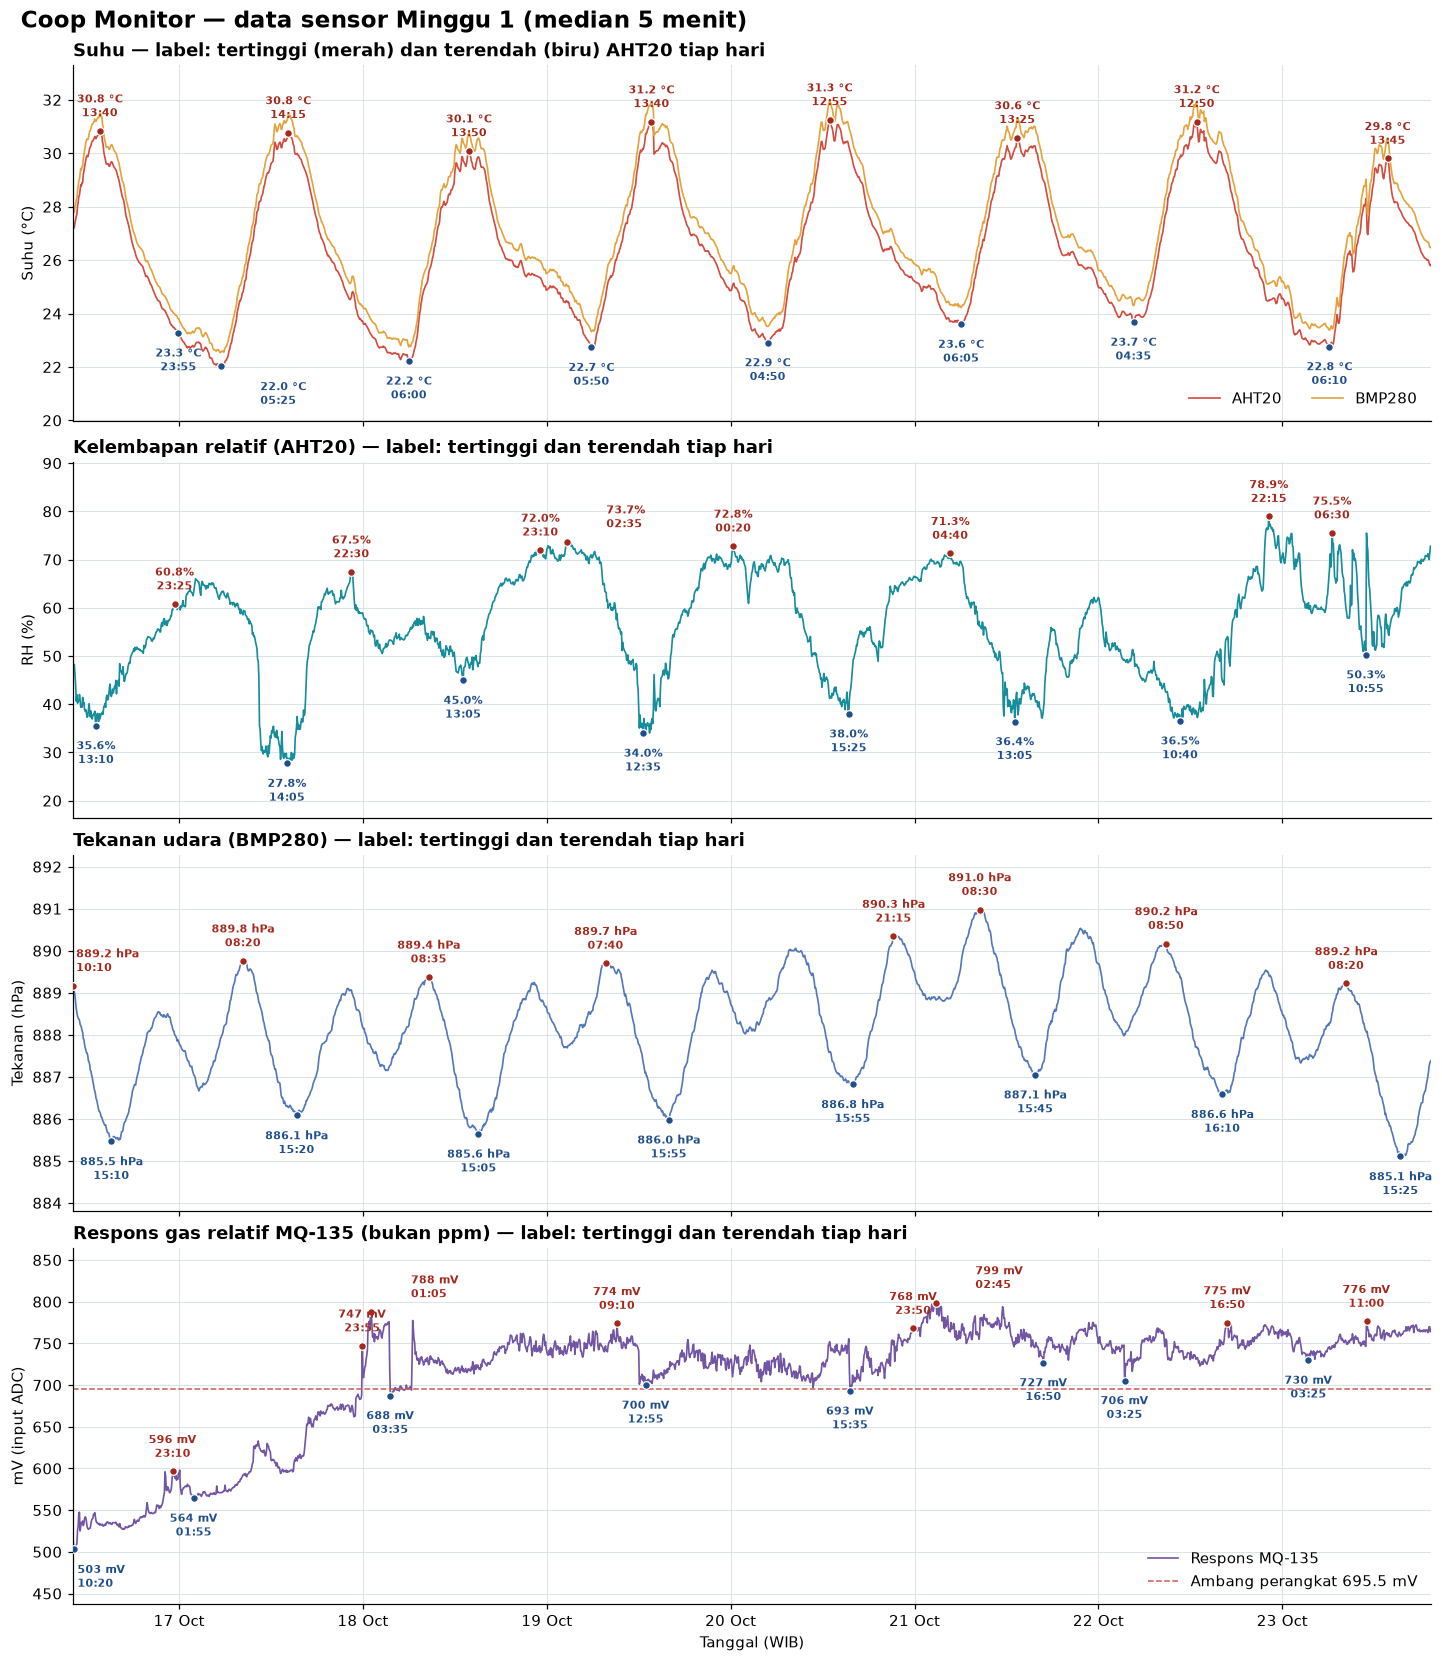

,Tekanan (hPa) maks,jam Tekanan (hPa) maks,Tekanan (hPa) min,jam Tekanan (hPa) min,MQ-135 (mV) maks,jam MQ-135 (mV) maks,MQ-135 (mV) min,jam MQ-135 (mV) min
16 Oct,889.2,10:10,885.5,15:10,596.0,23:10,503.0,10:20
17 Oct,889.8,08:20,886.1,15:20,747.0,23:55,564.0,01:55
18 Oct,889.4,08:35,885.6,15:05,788.0,01:05,688.0,03:35
19 Oct,889.7,07:40,886.0,15:55,774.0,09:10,700.0,12:55
20 Oct,890.3,21:15,886.8,15:55,768.0,23:50,693.0,15:35
21 Oct,891.0,08:30,887.1,15:45,799.0,02:45,727.0,16:50
22 Oct,890.2,08:50,886.6,16:10,775.0,16:50,706.0,03:25
23 Oct,889.2,08:20,885.1,15:25,776.0,11:00,730.0,03:25


In [2]:
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white', 'axes.titleweight': 'bold'})

def time_axis(ax):
    ax.xaxis.set_major_locator(mdates.DayLocator(tz=TZ))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b', tz=TZ))
    ax.grid(True, color='#dce3e7', linewidth=.7)
    ax.margins(x=0)

def mark_daily(ax, s, unit, color, kind='max', dp=1, above=None):
    # Tandai puncak (kind='max') atau titik terendah (kind='min') setiap hari: nilai dan jam WIB
    if above is None:
        above = kind == 'max'
    prev = None
    for _, day in s.dropna().groupby(s.dropna().index.date):
        t = day.idxmax() if kind == 'max' else day.idxmin()
        v = day.loc[t]
        dx, ha = 0, 'center'
        if prev is not None and (t - prev) < pd.Timedelta(hours=8):
            dx, ha = 26, 'left'   # geser label agar tidak menumpuk dengan label hari sebelumnya
        if t - s.index.min() < pd.Timedelta(hours=3):
            dx, ha = 2, 'left'    # titik di tepi kiri grafik
        elif s.index.max() - t < pd.Timedelta(hours=3):
            dx, ha = -2, 'right'  # titik di tepi kanan grafik
        ax.plot(t, v, 'o', ms=5, color=color, mec='white', mew=.8, zorder=5)
        ax.annotate(f'{v:.{dp}f}{unit}\n{t:%H:%M}', (t, v), textcoords='offset points',
                    xytext=(dx, 7 if above else -9), ha=ha, va='bottom' if above else 'top',
                    fontsize=7.5, color=color, fontweight='bold', zorder=6)
        prev = t

def mark_peaks_lows(ax, s, unit, dp=1, hi_color='#a5281c', lo_color='#1f4e8c', pad=.22):
    # Label puncak (atas) dan terendah (bawah) setiap hari, lalu beri ruang di atas/bawah untuk label
    mark_daily(ax, s, unit, hi_color, 'max', dp)
    mark_daily(ax, s, unit, lo_color, 'min', dp)
    lo, hi = s.min(), s.max(); span = hi - lo
    ax.set_ylim(lo - pad * span, hi + pad * span)

device_thr = float(df['mqThresholdMv'].iloc[0])
fig, axs = plt.subplots(4, 1, figsize=(13, 15), sharex=True, layout='constrained')
axs[0].plot(b.index, b.temp, color='#d34c40', lw=1.1, label='AHT20')
axs[0].plot(b.index, b.temp_bmp, color='#e4a33c', lw=1.1, label='BMP280')
mark_peaks_lows(axs[0], b.temp, ' °C')
axs[0].set_ylabel('Suhu (°C)'); axs[0].set_title('Suhu — label: tertinggi (merah) dan terendah (biru) AHT20 tiap hari', loc='left'); axs[0].legend(frameon=False, loc='lower right', ncol=2)
axs[1].plot(b.index, b.rh, color='#168d9b', lw=1.1)
mark_peaks_lows(axs[1], b.rh, '%')
axs[1].set_ylabel('RH (%)'); axs[1].set_title('Kelembapan relatif (AHT20) — label: tertinggi dan terendah tiap hari', loc='left')
axs[2].plot(b.index, b.press, color='#5278b7', lw=1.1)
mark_peaks_lows(axs[2], b.press, ' hPa')
axs[2].set_ylabel('Tekanan (hPa)'); axs[2].set_title('Tekanan udara (BMP280) — label: tertinggi dan terendah tiap hari', loc='left')
axs[3].plot(b.index, b.mq, color='#7256a4', lw=1.1, label='Respons MQ-135')
axs[3].axhline(device_thr, color='#d05a50', ls='--', lw=1, label=f'Ambang perangkat {device_thr:.1f} mV')
mark_peaks_lows(axs[3], b.mq, ' mV', dp=0)
axs[3].set_ylabel('mV (input ADC)'); axs[3].set_title('Respons gas relatif MQ-135 (bukan ppm) — label: tertinggi dan terendah tiap hari', loc='left'); axs[3].legend(frameon=False, loc='lower right')
for ax in axs: time_axis(ax)
axs[3].set_xlabel('Tanggal (WIB)')
fig.suptitle('Coop Monitor — data sensor Minggu 1 (median 5 menit)', x=.01, ha='left', fontsize=15, fontweight='bold')
plt.show()

def daily_extreme(s, kind):
    g = s.groupby(s.index.date)
    t = g.idxmax() if kind == 'max' else g.idxmin()
    return pd.DataFrame({'nilai': [s.loc[x] for x in t], 'jam': [x.strftime('%H:%M') for x in t]}, index=t.index)

def extremes_table(cols):
    # cols: {nama tampilan: (series, desimal)}
    parts = {}
    for name, (s, dp) in cols.items():
        for kind, lab in [('max', 'maks'), ('min', 'min')]:
            e = daily_extreme(s, kind)
            parts[f'{name} {lab}'] = e.nilai.round(dp)
            parts[f'jam {name} {lab}'] = e.jam
    out = pd.DataFrame(parts)
    out.index = [pd.Timestamp(d).strftime('%d %b') for d in out.index]
    return out

print('Puncak dan titik terendah harian (16 Okt mulai 10:10 dan 23 Okt berhenti 19:25 WIB, jadi kedua hari itu tidak lengkap):')
display(extremes_table({'Tekanan (hPa)': (b.press, 1), 'MQ-135 (mV)': (b.mq, 0)}))

## 3. Batas lingkungan dari jurnal

Tabel di bawah merangkum batas yang dipakai sebagai acuan. Kolom **Status verifikasi** menjelaskan seberapa kuat setiap angka sudah dicek; tidak semua angka bisa dibaca langsung dari teks lengkap jurnal.

| Parameter | Batas acuan | Sumber | Status verifikasi |
|---|---|---|---|
| Suhu zona termonetral (*thermoneutral zone*) ayam petelur | 19–22 °C | Avi (2024) [R1], hlm. 56; Kim dkk. (2024) [R3] menyebut rentang yang sama untuk ayam secara umum | DOI dicek di Crossref; teks lengkap kedua artikel dicek (23 Nov 2026) |
| Pengaruh RH pada stres panas | RH tinggi membatasi pelepasan panas lewat penguapan, sehingga suhu tinggi + RH tinggi paling berbahaya | Brugaletta dkk. (2022) [R2] | DOI dan isi teks dicek (pernyataan kualitatif, tanpa angka) |
| *Temperature-Humidity Index* (THI) ayam petelur | Nyaman < 70; waspada 70–75; bahaya 76–81; darurat > 81 | Kim dkk. (2024) [R3], mengutip Zulovich & DeShazer (1990) | DOI dan teks lengkap dicek |
| Amonia (NH₃) di kandang | Dijaga di bawah 25 ppm; paparan lama di atas 25 ppm menurunkan pertumbuhan dan memicu infeksi saluran napas | Bist dkk. (2023) [R4] | DOI dicek; angka dari kutipan sekunder |
| RH kandang | Sekitar 40–60%; di atas 60% kualitas litter dan udara cenderung buruk | Penyuluhan University of Georgia (B. Fairchild) | **Bukan jurnal, tidak ber-DOI.** Belum ditemukan jurnal 2021–2026 ber-DOI yang memberi rentang RH tertentu |

Rumus THI yang dipakai adalah bentuk NRC (1971) dalam °F, yang skalanya sesuai dengan kategori di atas:

$$\mathrm{THI} = T_F - (0{,}55 - 0{,}0055\,\mathrm{RH})\,(T_F - 58), \qquad T_F = 1{,}8\,T_{^\circ C} + 32$$

Kim dkk. (2024) menyebut memakai rumus NRC (1971), tetapi tidak menuliskan rumusnya di artikel. Jadi rumus di atas adalah bentuk standar NRC (1971), bukan kutipan langsung dari artikel itu.

**Kenapa batas suhu ayam petelur, bukan broiler.** Kandang yang dipantau berisi **ayam petelur**. Versi notebook sebelumnya memakai zona nyaman broiler 21–28 °C; batas itu tidak berlaku untuk ayam petelur dan sudah diganti. Zona termonetral 19–22 °C dipakai sebagai batas suhu, sedangkan **penilaian stres panas memakai kategori THI ayam petelur** [R3], karena THI memperhitungkan suhu dan kelembapan sekaligus.

Puncak dan titik terendah harian (16 Okt mulai 10:10 dan 23 Okt berhenti 19:25 WIB, jadi kedua hari itu tidak lengkap):


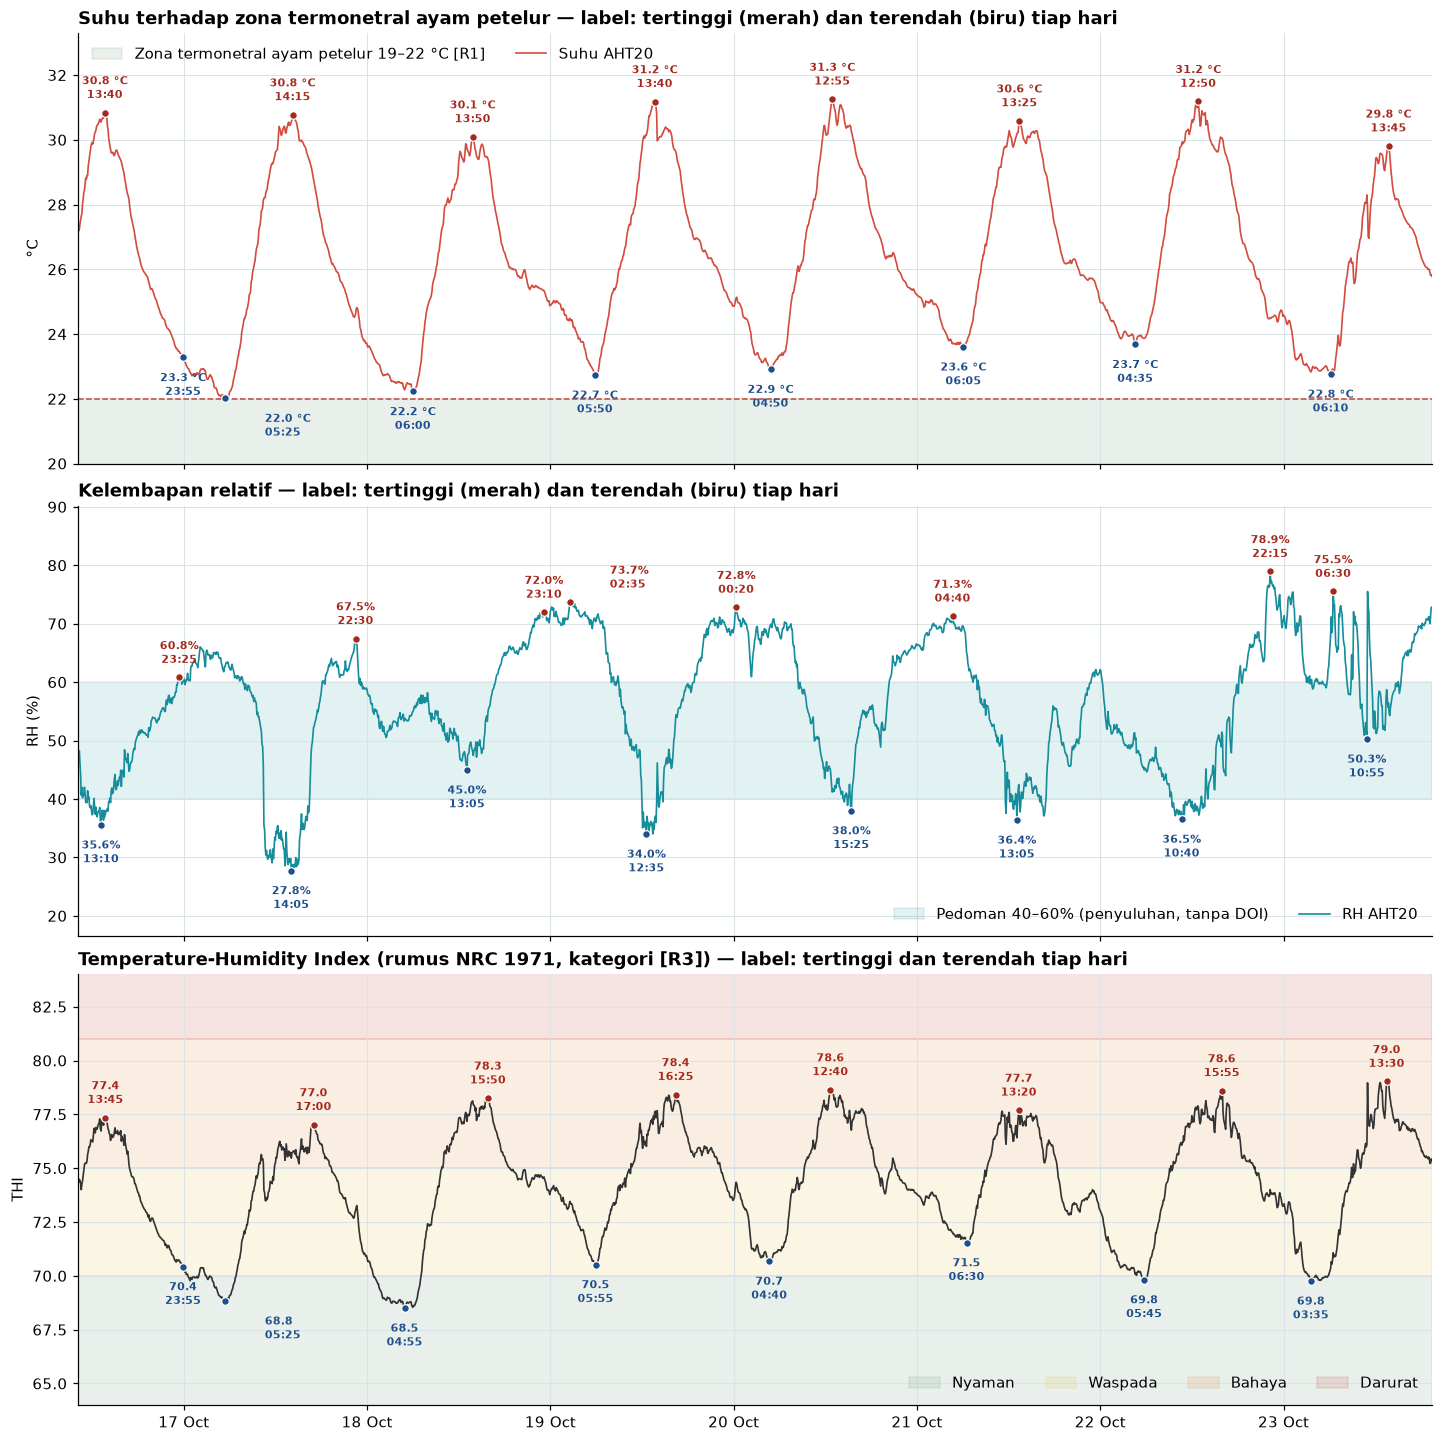

,Suhu (°C) maks,jam Suhu (°C) maks,Suhu (°C) min,jam Suhu (°C) min,RH (%) maks,jam RH (%) maks,RH (%) min,jam RH (%) min,THI maks,jam THI maks,THI min,jam THI min
16 Oct,30.8,13:40,23.3,23:55,60.8,23:25,35.6,13:10,77.4,13:45,70.4,23:55
17 Oct,30.8,14:15,22.0,05:25,67.5,22:30,27.8,14:05,77.0,17:00,68.8,05:25
18 Oct,30.1,13:50,22.2,06:00,72.0,23:10,45.0,13:05,78.3,15:50,68.5,04:55
19 Oct,31.2,13:40,22.7,05:50,73.7,02:35,34.0,12:35,78.4,16:25,70.5,05:55
20 Oct,31.3,12:55,22.9,04:50,72.8,00:20,38.0,15:25,78.6,12:40,70.7,04:40
21 Oct,30.6,13:25,23.6,06:05,71.3,04:40,36.4,13:05,77.7,13:20,71.5,06:30
22 Oct,31.2,12:50,23.7,04:35,78.9,22:15,36.5,10:40,78.6,15:55,69.8,05:45
23 Oct,29.8,13:45,22.8,06:10,75.5,06:30,50.3,10:55,79.0,13:30,69.8,03:35


,Kriteria,% waktu
0,Suhu di atas 22 °C,100.0
1,Suhu di zona 19–22 °C,0.0
2,Suhu di bawah 19 °C,0.0
3,RH di atas 60%,41.6
4,RH 40–60%,48.4
5,RH di bawah 40%,10.0
6,THI Nyaman,8.2
7,THI Waspada,49.6
8,THI Bahaya,42.2
9,THI Darurat,0.0


In [3]:
TN_LOW, TN_HIGH = 19.0, 22.0      # zona termonetral ayam petelur [R1]
RH_LOW, RH_HIGH = 40.0, 60.0      # pedoman penyuluhan UGA (tanpa DOI)
THI_BANDS = [(-np.inf, 70, 'Nyaman', '#6f9e7a'), (70, 75, 'Waspada', '#e5c04a'),
             (75, 81, 'Bahaya', '#e08a3c'), (81, np.inf, 'Darurat', '#c2453a')]   # [R3]

def thi_nrc(t_c, rh):
    tf = 1.8 * t_c + 32
    return tf - (0.55 - 0.0055 * rh) * (tf - 58)

b['thi'] = thi_nrc(b.temp, b.rh)

fig, axs = plt.subplots(3, 1, figsize=(13, 13), sharex=True, layout='constrained')
ax = axs[0]
ax.axhspan(TN_LOW, TN_HIGH, color='#6f9e7a', alpha=.15, label=f'Zona termonetral ayam petelur {TN_LOW:.0f}–{TN_HIGH:.0f} °C [R1]')
ax.plot(b.index, b.temp, color='#d34c40', lw=1.1, label='Suhu AHT20')
ax.axhline(TN_HIGH, color='#c2453a', ls='--', lw=1)
mark_peaks_lows(ax, b.temp, ' °C')
ax.set_ylabel('°C'); ax.set_title('Suhu terhadap zona termonetral ayam petelur — label: tertinggi (merah) dan terendah (biru) tiap hari', loc='left'); ax.legend(frameon=False, loc='upper left', ncol=2)
ax = axs[1]
ax.axhspan(RH_LOW, RH_HIGH, color='#168d9b', alpha=.12, label='Pedoman 40–60% (penyuluhan, tanpa DOI)')
ax.plot(b.index, b.rh, color='#168d9b', lw=1.1, label='RH AHT20')
mark_peaks_lows(ax, b.rh, '%')
ax.set_ylabel('RH (%)'); ax.set_title('Kelembapan relatif — label: tertinggi (merah) dan terendah (biru) tiap hari', loc='left'); ax.legend(frameon=False, loc='lower right', ncol=2)
ax = axs[2]
for lo, hi, name, col in THI_BANDS:
    ax.axhspan(max(lo, 60), min(hi, 90), color=col, alpha=.15, label=f'{name}')
ax.plot(b.index, b.thi, color='#333', lw=1.1)
mark_peaks_lows(ax, b.thi, '')
ax.set_ylim(64, 84); ax.set_ylabel('THI'); ax.set_title('Temperature-Humidity Index (rumus NRC 1971, kategori [R3]) — label: tertinggi dan terendah tiap hari', loc='left')
ax.legend(frameon=False, ncol=4, loc='lower right')
for ax in axs: time_axis(ax)
plt.show()

print('Puncak dan titik terendah harian (16 Okt mulai 10:10 dan 23 Okt berhenti 19:25 WIB, jadi kedua hari itu tidak lengkap):')
display(extremes_table({'Suhu (°C)': (b.temp, 1), 'RH (%)': (b.rh, 1), 'THI': (b.thi, 1)}))

def share(mask): return 100 * mask.mean()
summary = pd.DataFrame({
    'Kriteria': ['Suhu di atas 22 °C', 'Suhu di zona 19–22 °C', 'Suhu di bawah 19 °C',
                 'RH di atas 60%', 'RH 40–60%', 'RH di bawah 40%'] + [f'THI {n}' for _, _, n, _ in THI_BANDS],
    '% waktu': [share(b.temp > TN_HIGH), share(b.temp.between(TN_LOW, TN_HIGH)), share(b.temp < TN_LOW),
                share(b.rh > RH_HIGH), share(b.rh.between(RH_LOW, RH_HIGH)), share(b.rh < RH_LOW)]
               + [share((b.thi >= lo) & (b.thi < hi)) for lo, hi, _, _ in THI_BANDS]})
summary['% waktu'] = summary['% waktu'].round(1)
summary

## 3A. Insight: kapan kondisi kandang kritis?

Bagian ini membaca data memakai **batas dari publikasi** (bukan garis statistik): kategori THI ayam petelur [R3] sebagai ukuran utama stres panas, suhu 22 °C sebagai batas atas zona termonetral ayam petelur [R1], dan RH 60% (pedoman penyuluhan). Suhu kandang **tidak pernah** turun ke 22 °C atau di bawahnya selama Minggu 1 (minimum 22,0 °C pada 17 Okt 05:25), jadi batas suhu terlewati sepanjang waktu dan tidak bisa membedakan jam. Pembeda jam kritis adalah THI. Heatmap hari × jam di bawah menunjukkan **pada jam berapa** setiap batas terlewati, dan profil per jam merangkum pola rata-rata seminggu.

Batas kategori THI di artikel [R3] tertulis 70–75 (waspada) dan 76–81 (bahaya), dengan celah antara 75 dan 76. Notebook ini memakai 75 sebagai awal kategori bahaya, pilihan yang lebih hati-hati.

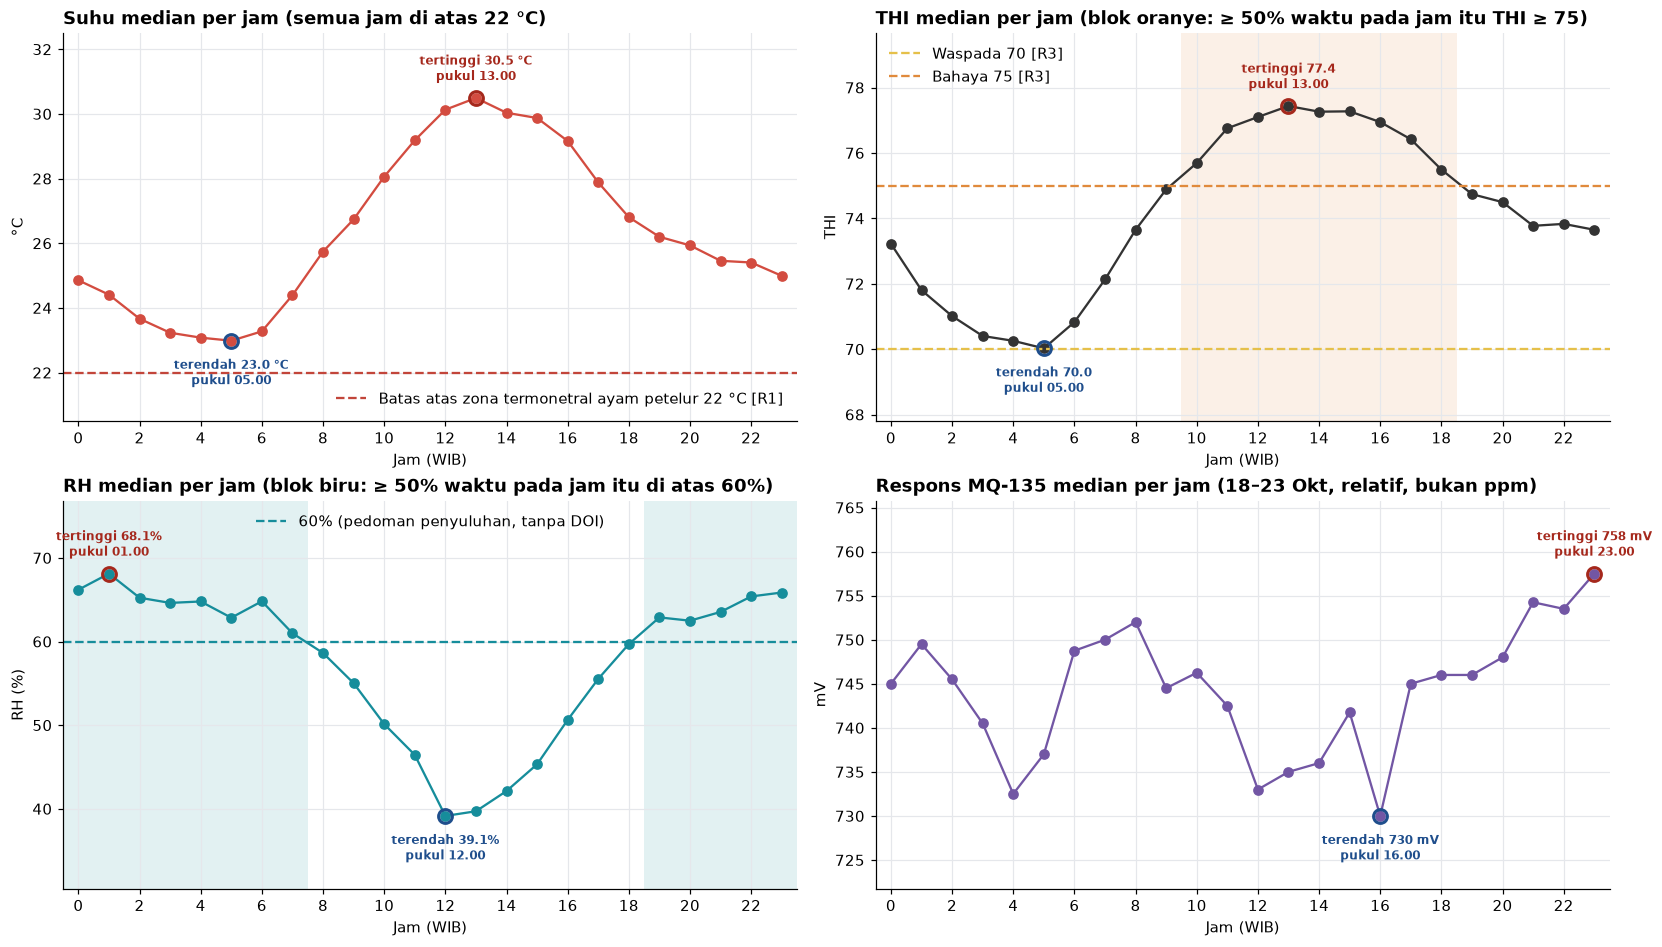

,n_hari,n_interval_5mnt,suhu_median,pct_suhu_lebih_22,thi_median,pct_thi_bahaya,rh_median,pct_rh_lebih_60,mq_median_stabil
hour,,,,,,,,,
0,7,84,24.9,100.0,73.2,0.0,66.2,73.8,745.0
1,7,84,24.4,100.0,71.8,0.0,68.1,71.4,749.5
2,7,84,23.7,100.0,71.0,0.0,65.2,71.4,745.5
3,7,84,23.2,100.0,70.4,0.0,64.6,63.1,740.5
4,7,84,23.1,100.0,70.3,0.0,64.8,64.3,732.5
5,7,84,23.0,100.0,70.0,0.0,62.8,61.9,737.0
6,7,84,23.3,100.0,70.8,0.0,64.8,71.4,748.8
7,7,84,24.4,100.0,72.1,0.0,61.0,66.7,750.0
8,7,84,25.7,100.0,73.6,1.2,58.6,22.6,752.0


In [4]:
b['hour'] = b.index.hour
hourly = b.groupby('hour').agg(
    n_hari=('date', 'nunique'),
    n_interval_5mnt=('temp', 'size'),
    suhu_median=('temp', 'median'),
    pct_suhu_lebih_22=('temp', lambda s: 100 * (s > TN_HIGH).mean()),
    thi_median=('thi', 'median'),
    pct_thi_bahaya=('thi', lambda s: 100 * (s >= 75).mean()),
    rh_median=('rh', 'median'),
    pct_rh_lebih_60=('rh', lambda s: 100 * (s > RH_HIGH).mean()),
    mq_median_stabil=('mq', lambda s: s[s.index >= pd.Timestamp('2026-10-18', tz=TZ)].median()))

fig, axs = plt.subplots(2, 2, figsize=(15, 8.5), layout='constrained')
hrs = hourly.index
def shade_hours(ax, mask, color):
    for h in hrs[mask]:
        ax.axvspan(h - .5, h + .5, color=color, alpha=.12, lw=0)
ax = axs[0, 0]
ax.plot(hrs, hourly.suhu_median, 'o-', color='#d34c40'); ax.axhline(TN_HIGH, color='#c2453a', ls='--', label='Batas atas zona termonetral ayam petelur 22 °C [R1]')
ax.set_title('Suhu median per jam (semua jam di atas 22 °C)', loc='left'); ax.set_ylabel('°C'); ax.legend(frameon=False, loc='lower right')
ax = axs[0, 1]
shade_hours(ax, hourly.pct_thi_bahaya >= 50, '#e08a3c')
ax.plot(hrs, hourly.thi_median, 'o-', color='#333'); ax.axhline(70, color='#e5c04a', ls='--', label='Waspada 70 [R3]'); ax.axhline(75, color='#e08a3c', ls='--', label='Bahaya 75 [R3]')
ax.set_title('THI median per jam (blok oranye: ≥ 50% waktu pada jam itu THI ≥ 75)', loc='left'); ax.set_ylabel('THI'); ax.legend(frameon=False)
ax = axs[1, 0]
shade_hours(ax, hourly.pct_rh_lebih_60 >= 50, '#168d9b')
ax.plot(hrs, hourly.rh_median, 'o-', color='#168d9b'); ax.axhline(RH_HIGH, color='#168d9b', ls='--', label='60% (pedoman penyuluhan, tanpa DOI)')
ax.set_title('RH median per jam (blok biru: ≥ 50% waktu pada jam itu di atas 60%)', loc='left'); ax.set_ylabel('RH (%)'); ax.legend(frameon=False)
ax = axs[1, 1]
ax.plot(hrs, hourly.mq_median_stabil, 'o-', color='#7256a4')
ax.set_title('Respons MQ-135 median per jam (18–23 Okt, relatif, bukan ppm)', loc='left'); ax.set_ylabel('mV')

def mark_hourly(ax, s, unit, dp=1):
    # Label jam dengan median tertinggi dan terendah
    lo, hi = s.min(), s.max(); span = hi - lo
    for h, above, col in [(s.idxmax(), True, '#a5281c'), (s.idxmin(), False, '#1f4e8c')]:
        v = s.loc[h]
        ax.plot(h, v, 'o', ms=9, mfc='none', mec=col, mew=2, zorder=5)
        ax.annotate(f'{"tertinggi" if above else "terendah"} {v:.{dp}f}{unit}\npukul {h:02d}.00', (h, v), textcoords='offset points',
                    xytext=(0, 9 if above else -11), ha='center', va='bottom' if above else 'top',
                    fontsize=8, color=col, fontweight='bold')
    ax.set_ylim(lo - .3 * span, hi + .3 * span)

mark_hourly(axs[0, 0], hourly.suhu_median, ' °C')
axs[0, 0].set_ylim(TN_HIGH - 1.5, hourly.suhu_median.max() + 2)   # garis 22 °C tetap terlihat
mark_hourly(axs[0, 1], hourly.thi_median, '')
mark_hourly(axs[1, 0], hourly.rh_median, '%')
mark_hourly(axs[1, 1], hourly.mq_median_stabil, ' mV', dp=0)
for ax in axs.ravel():
    ax.set_xticks(range(0, 24, 2)); ax.set_xlabel('Jam (WIB)'); ax.grid(True, color='#e5e7eb'); ax.set_xlim(-.5, 23.5)
plt.show()
hourly.round(1)

### Cara membaca tabel per jam di atas

**Data berasal dari hari apa?** Tabel ini menggabungkan **semua hari** 16–23 Oktober, bukan satu hari tertentu. Setiap baris berisi semua median 5 menit yang jatuh pada jam itu, dari setiap hari.

- Satu jam berisi 12 interval 5 menit (misalnya 09:00, 09:05, …, 09:55).
- Kolom `n_hari` adalah jumlah hari yang punya data pada jam itu, dan `n_interval_5mnt` adalah jumlah intervalnya. Jam 00–09 dan 20–23 hanya punya 7 hari (84 interval), karena data 16 Okt baru mulai pukul 10:10 dan 23 Okt berhenti pukul 19:25. Jam 10–18 punya 8 hari (sekitar 96 interval).
- Kolom `mq_median_stabil` hanya memakai 18–23 Okt, karena sebelum itu sensor MQ-135 masih dalam masa pemanasan.

**Arti kolom median (`suhu_median`, `thi_median`, `rh_median`).** Nilai tengah dari semua interval pada jam itu. Contoh: `thi_median` = 77,4 pada jam 13 artinya separuh dari semua interval pukul 13:00–13:55, dari semua hari, punya THI di atas 77,4.

**Arti kolom persentase (`pct_…`).** Ini **bukan nilai THI, suhu, atau RH**. Ini **berapa persen waktu** pada jam itu yang sudah melewati batas literatur:

$$\texttt{pct\_thi\_bahaya} = \frac{\text{jumlah interval 5 menit dengan THI} \geq 75}{\text{jumlah semua interval 5 menit pada jam itu}} \times 100\%$$

Cara membaca angkanya:

| Nilai | Artinya |
|---|---|
| 0% | Sepanjang jam itu, di semua hari, batas tidak pernah terlewati |
| 100% | Sepanjang jam itu, di semua hari, batas terlewati tanpa jeda |
| di antaranya | **Jam peralihan**: nilainya menyeberangi batas di tengah jam, dan menit penyeberangannya berbeda setiap hari |

Contohnya jam 9 (`pct_thi_bahaya` 42,9%): THI naik pelan setiap pagi dan melewati 75 di tengah-tengah jam 9. Sel di bawah merinci jam 9 per hari dan per interval 5 menit, supaya terlihat dari mana angka 42,9% berasal. Jam 12–15 bernilai 100% karena pada keempat jam itu THI sudah di atas 75 dari menit pertama sampai menit terakhir, di semua hari. Sore hari terjadi kebalikannya (jam 16–22 turun dari 99% ke 5%), saat THI turun kembali di bawah 75.

Kolom `pct_suhu_lebih_22` dan `pct_rh_lebih_60` dibaca dengan cara yang sama, dengan batas 22 °C dan 60% RH. Kolom `pct_suhu_lebih_22` bernilai 100% pada semua jam, karena suhu kandang selalu di atas zona termonetral ayam petelur.

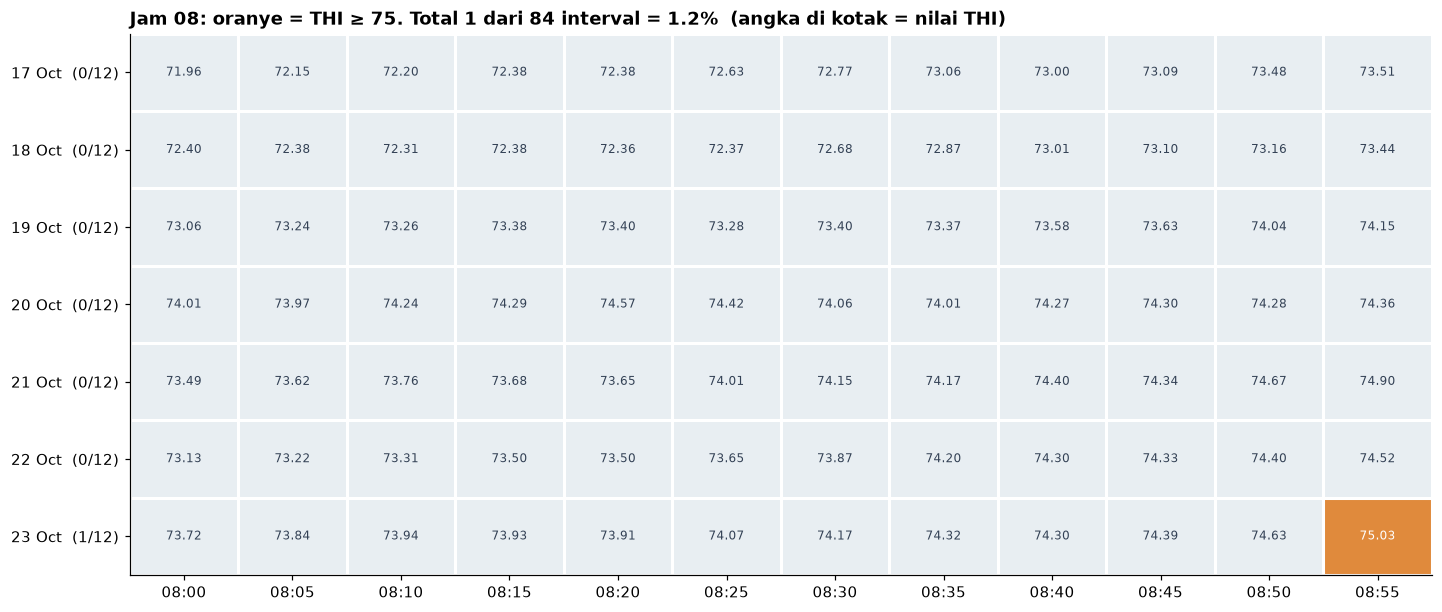

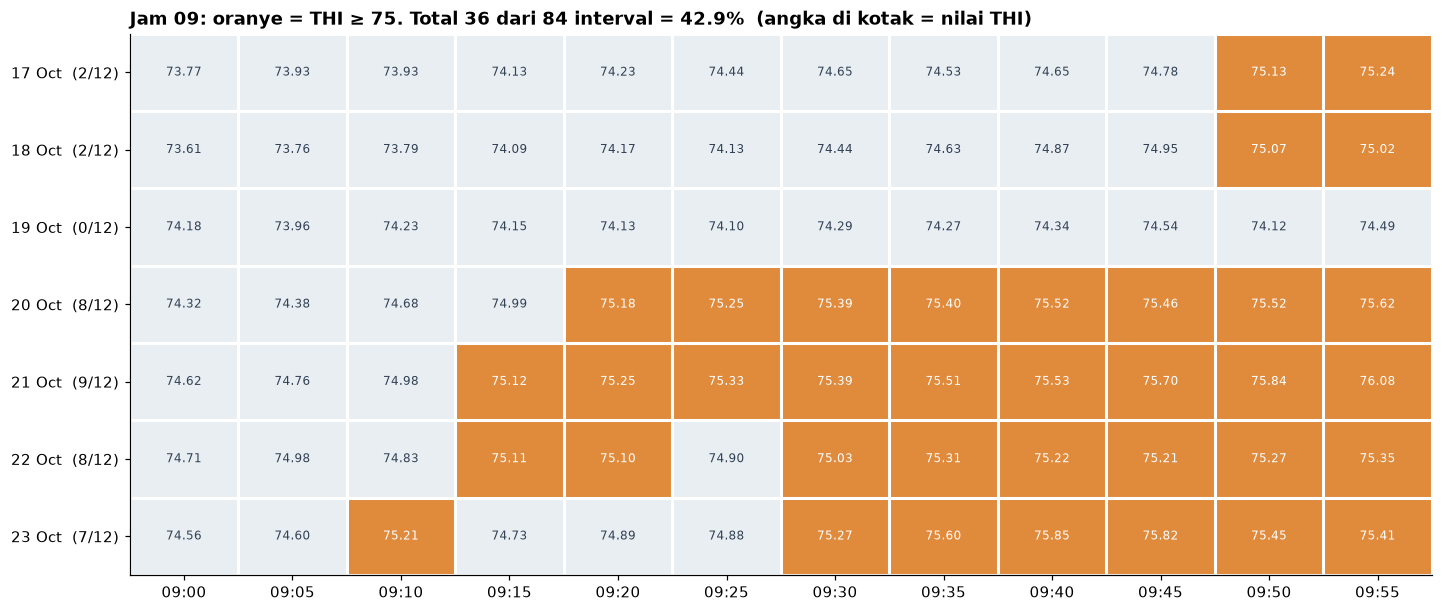

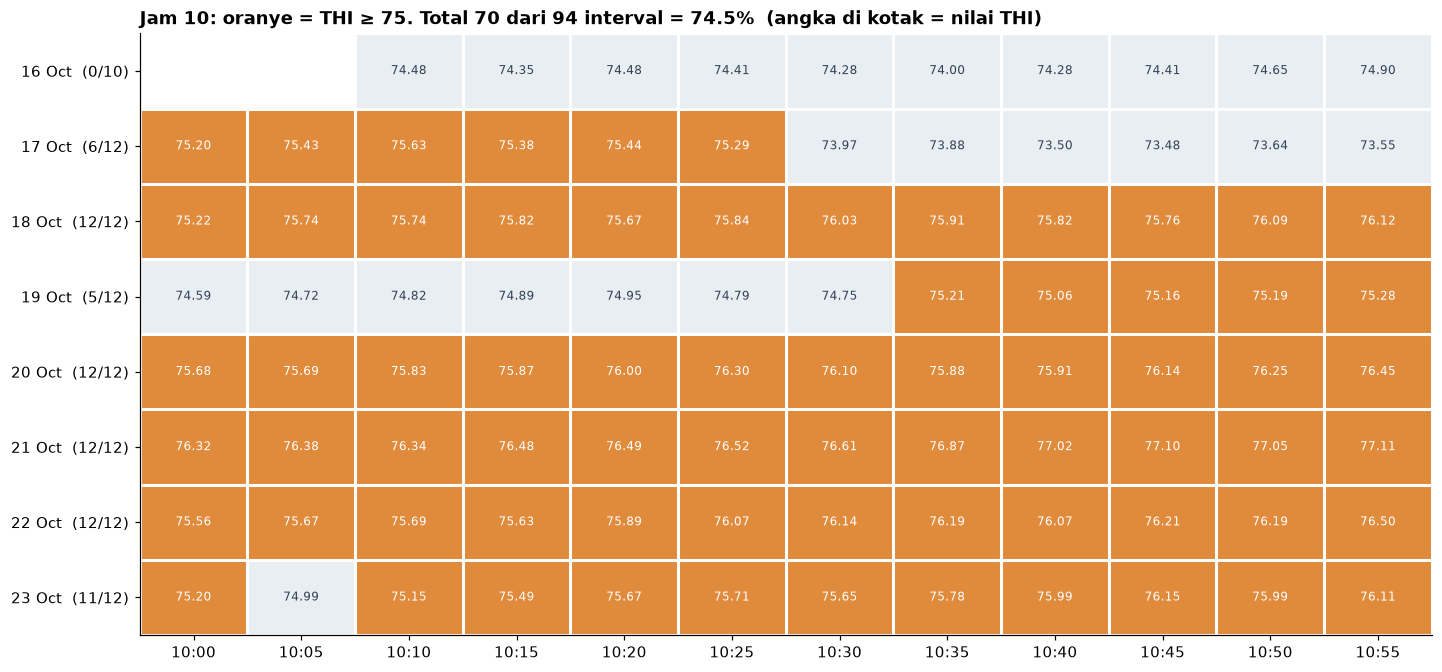

In [5]:
# Rincian jam peralihan: setiap kotak adalah satu interval 5 menit, merah jika THI >= 75
def transition_grid(hour, col='thi', thr=75, label='THI ≥ 75'):
    h = b[b.index.hour == hour]
    days = sorted(h['date'].unique())
    M = np.full((len(days), 12), np.nan)
    V = np.full((len(days), 12), np.nan)
    for i, d in enumerate(days):
        g = h[h['date'] == d]
        for t, v in g[col].items():
            M[i, t.minute // 5] = v >= thr
            V[i, t.minute // 5] = v
    fig, ax = plt.subplots(figsize=(13, .55 * len(days) + 1.6), layout='constrained')
    cmap = matplotlib.colors.ListedColormap(['#e8eef2', '#e08a3c'])
    ax.imshow(np.ma.masked_invalid(M), cmap=cmap, vmin=0, vmax=1, aspect='auto')
    for i in range(len(days)):
        for j in range(12):
            if np.isfinite(V[i, j]):
                ax.text(j, i, f'{V[i, j]:.2f}', ha='center', va='center', fontsize=8,
                        color='white' if M[i, j] == 1 else '#334155')
    n_yes = int(np.nansum(M)); n_all = int(np.isfinite(M).sum())
    rows = [f'{pd.Timestamp(d):%d %b}  ({int(np.nansum(M[i]))}/{int(np.isfinite(M[i]).sum())})' for i, d in enumerate(days)]
    ax.set_yticks(range(len(days)), rows)
    ax.set_xticks(range(12), [f'{hour:02d}:{m:02d}' for m in range(0, 60, 5)])
    ax.set_xticks(np.arange(-.5, 12, 1), minor=True); ax.set_yticks(np.arange(-.5, len(days), 1), minor=True)
    ax.grid(which='minor', color='white', lw=2); ax.tick_params(which='minor', length=0)
    ax.set_title(f'Jam {hour:02d}: oranye = {label}. Total {n_yes} dari {n_all} interval = {100 * n_yes / n_all:.1f}%  '
                 f'(angka di kotak = nilai {col.upper()})', loc='left')
    plt.show()

import matplotlib.colors
for hr in (8, 9, 10):
    transition_grid(hr)

Pada grid di atas, setiap baris adalah satu hari dan setiap kotak adalah satu interval 5 menit. Angka di samping tanggal adalah jumlah kotak oranye dibanding jumlah kotak pada hari itu. **Persentase di tabel per jam = jumlah semua kotak oranye ÷ jumlah semua kotak.** Jam 8 hampir seluruhnya abu-abu (1,2%), jam 9 setengah-setengah (42,9%), dan jam 10 sebagian besar sudah oranye (74,5%).

Grid jam 9 juga memperlihatkan tiga hal lain:
- **Nilainya sangat dekat dengan batas.** Kebanyakan kotak berada di antara 74,5 dan 75,5, padahal ketidakpastian THI dari akurasi AHT20 (±0,3 °C dan ±2 %RH) sekitar ±0,5. Jadi jam 9 sebaiknya dibaca "mendekati batas bahaya", bukan "sudah pasti bahaya".
- **THI bisa naik-turun melewati 75** sebelum benar-benar menetap di atasnya. Contohnya 23 Okt: 75,2 pada 09:10, turun lagi ke bawah 75, lalu menetap di atas 75 mulai 09:30.
- **Mulai 20 Okt, THI masuk kategori bahaya lebih pagi** (sekitar 09:10–09:20) dibanding 17–18 Okt (09:50). Itulah sebabnya jam 9 punya porsi oranye yang cukup besar.

Tabel berikut menunjukkan **pada menit berapa** THI menyeberangi 75 setiap hari: kapan masuk kategori bahaya pada pagi atau siang hari, kapan keluar pada sore atau malam hari, dan berapa lama totalnya.

In [6]:
def crossings(col='thi', thr=75):
    rows = []
    for d, g in b.groupby('date'):
        above = g[col] >= thr
        if not above.any():
            rows.append({'tanggal': pd.Timestamp(d).strftime('%d %b'), 'pertama ≥ 75': '-', 'terakhir ≥ 75': '-', 'total jam ≥ 75': 0.0})
            continue
        rows.append({'tanggal': pd.Timestamp(d).strftime('%d %b'),
                     'pertama ≥ 75': g.index[above.values][0].strftime('%H:%M'),
                     'terakhir ≥ 75': g.index[above.values][-1].strftime('%H:%M'),
                     'total jam ≥ 75': round(above.sum() * 5 / 60, 1),
                     'data mulai': g.index.min().strftime('%H:%M'), 'data berakhir': g.index.max().strftime('%H:%M')})
    return pd.DataFrame(rows).set_index('tanggal')

crossings()

,pertama ≥ 75,terakhir ≥ 75,total jam ≥ 75,data mulai,data berakhir
tanggal,,,,,
16 Oct,11:00,16:50,5.9,10:10,23:55
17 Oct,09:50,19:20,8.2,00:00,23:55
18 Oct,09:50,18:35,8.8,00:00,23:55
19 Oct,10:35,22:15,11.8,00:00,23:55
20 Oct,09:20,21:10,9.9,00:00,23:55
21 Oct,09:15,18:20,9.2,00:00,23:55
22 Oct,09:15,20:15,10.9,00:00,23:55
23 Oct,08:55,19:25,10.1,00:00,19:25


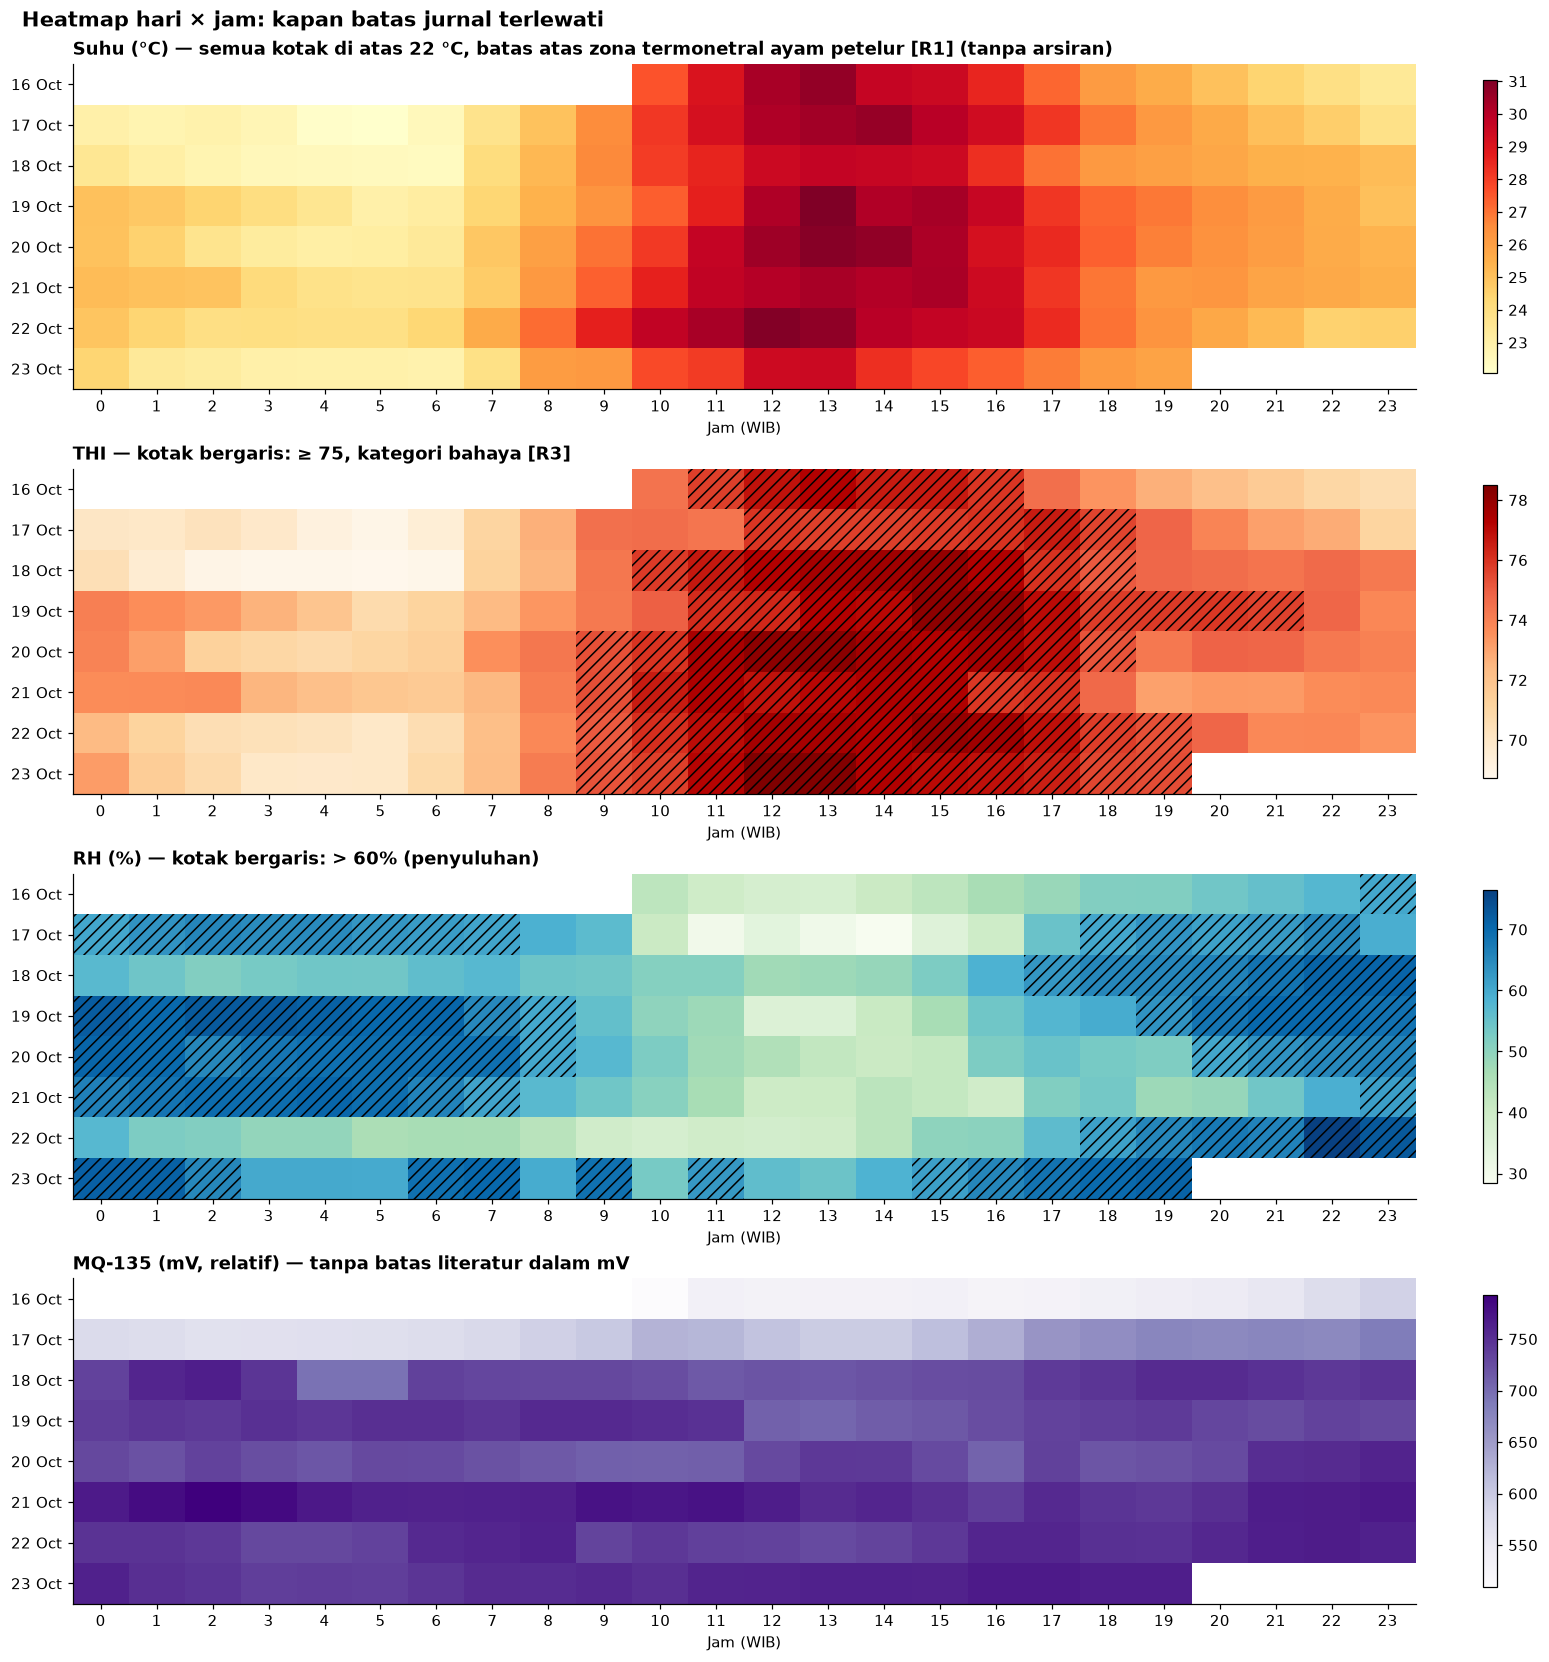

,jam data,jam suhu > 22 °C,suhu min (°C),jam THI ≥ 75,THI maksimum,jam RH > 60%,suhu maks (°C)
date,,,,,,,
2026-10-16,13.8,13.8,23.3,5.9,77.4,0.7,30.8
2026-10-17,24.0,24.0,22.0,8.2,77.0,12.5,30.8
2026-10-18,24.0,24.0,22.2,8.8,78.3,7.2,30.1
2026-10-19,24.0,24.0,22.7,11.8,78.4,13.8,31.2
2026-10-20,24.0,24.0,22.9,9.9,78.6,12.1,31.3
2026-10-21,24.0,24.0,23.6,9.2,77.7,9.1,30.6
2026-10-22,24.0,24.0,23.7,10.9,78.6,6.1,31.2
2026-10-23,19.5,19.5,22.8,10.1,79.0,12.4,29.8


In [7]:
def day_hour(col, agg='median'):
    t = b.assign(day=b.index.strftime('%d %b'), hour=b.index.hour)
    return t.pivot_table(index='day', columns='hour', values=col, aggfunc=agg).reindex(sorted(t['day'].unique(), key=lambda d: pd.Timestamp(d + ' 2026')))

panels = [('temp', 'Suhu (°C) — semua kotak di atas 22 °C, batas atas zona termonetral ayam petelur [R1] (tanpa arsiran)', 'YlOrRd', None),
          ('thi', 'THI — kotak bergaris: ≥ 75, kategori bahaya [R3]', 'OrRd', lambda v: v >= 75),
          ('rh', 'RH (%) — kotak bergaris: > 60% (penyuluhan)', 'GnBu', lambda v: v > RH_HIGH),
          ('mq', 'MQ-135 (mV, relatif) — tanpa batas literatur dalam mV', 'Purples', None)]
fig, axs = plt.subplots(4, 1, figsize=(14, 15), layout='constrained')
for ax, (col, title, cmap, rule) in zip(axs, panels):
    M = day_hour(col)
    im = ax.imshow(M.values, aspect='auto', cmap=cmap)
    ax.set_yticks(range(len(M.index)), M.index); ax.set_xticks(range(0, 24), range(0, 24))
    ax.set_xlabel('Jam (WIB)'); ax.set_title(title, loc='left')
    fig.colorbar(im, ax=ax, shrink=.9)
    if rule is not None:
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                v = M.values[i, j]
                if np.isfinite(v) and rule(v):
                    ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False, hatch='///', edgecolor='black', lw=0))
fig.suptitle('Heatmap hari × jam: kapan batas jurnal terlewati', x=.01, ha='left', fontsize=14, fontweight='bold')
plt.show()

per_day = pd.DataFrame({
    'jam data': b.groupby('date').temp.apply(lambda s: s.size * 5 / 60),
    'jam suhu > 22 °C': b.groupby('date').temp.apply(lambda s: (s > TN_HIGH).sum() * 5 / 60),
    'suhu min (°C)': b.groupby('date').temp.min(),
    'jam THI ≥ 75': b.groupby('date').thi.apply(lambda s: (s >= 75).sum() * 5 / 60),
    'THI maksimum': b.groupby('date').thi.max(),
    'jam RH > 60%': b.groupby('date').rh.apply(lambda s: (s > RH_HIGH).sum() * 5 / 60),
    'suhu maks (°C)': b.groupby('date').temp.max()}).round(1)
per_day

### Cerita data Minggu 1

**1. Suhu kandang selalu di atas zona termonetral ayam petelur.** Zona termonetral ayam petelur adalah 19–22 °C [R1]. Selama Minggu 1, suhu kandang **tidak pernah** turun ke 22 °C atau di bawahnya: titik terendah 22,0–23,7 °C menjelang subuh, dan puncak 30–31 °C sekitar pukul 13.00–14.00. Artinya ayam tidak pernah berada di zona termonetralnya, bahkan pada malam hari. Batas suhu saja tidak bisa menunjukkan jam mana yang paling berisiko, jadi jam kritis dibaca dari THI (poin 2).

**2. THI menunjukkan jendela stres panas pada siang hari.** Dengan kategori THI ayam petelur dari Kim dkk. (2024) [R3], kandang berada di kategori **bahaya** (THI ≥ 75) setiap siang pukul 12.00–16.00, dan sering juga pukul 10.00–18.00, yaitu sekitar 6–12 jam per hari. THI tidak pernah mencapai kategori darurat (maksimum 79,0 pada 23 Okt). Kim dkk. memakai kategori ini untuk menilai stres panas dalam penelitian performa bertelur, kualitas telur, dan respons fisiologis ayam petelur. Brugaletta dkk. (2022) [R2] menjelaskan sebabnya: kelembapan tinggi membatasi pelepasan panas lewat penguapan, sehingga ayam makin sulit mendinginkan tubuh.

**3. Malam hari punya risiko lain: udara lembap.** Dari pukul 19.00 sampai 07.00, RH berada di atas 60% pada sebagian besar hari (median 62–68%, mencapai 79% saat hujan 23 Okt). Pedoman penyuluhan menyebut RH di atas 60% sering berarti litter basah dan kualitas udara buruk. Kadar air litter tidak diukur di kandang ini, jadi kaitan antara malam yang lembap dan amonia masih berupa dugaan yang perlu dicek.

**4. Respons gas MQ-135 tinggi pada jam yang berbeda dari jam panas.** Pada periode stabil (18–23 Okt), median MQ paling rendah pada siang hari (730–736 mV) dan paling tinggi pada malam hari pukul 21.00–02.00 (745–758 mV) serta pagi pukul 06.00–08.00. Korelasi THI dengan MQ hampir nol (r ≈ −0,03). Artinya **ada dua jendela risiko terpisah**:
- **siang**: stres panas (THI di kategori bahaya),
- **malam sampai pagi**: udara lembap dan respons gas relatif tinggi.

Sebagian kenaikan MQ pada malam hari dijelaskan oleh kelembapan itu sendiri (sekitar +0,6 mV per poin RH, lihat bagian 4), karena sensor oksida logam ikut bereaksi pada uap air [R5]. Jadi nilai MQ yang tinggi pada malam yang lembap **belum tentu** berarti amonia lebih tinggi.

**5. Mulai 21 Oktober, respons gas bergeser naik.** Pada 21 Okt respons MQ berada di atas 754 mV selama sekitar 18 jam, dibanding kurang dari 5 jam per hari pada 18–20 Okt. Satu-satunya laporan bau menyengat (akhir 23 Okt) juga terjadi pada periode tinggi ini. Penyebabnya (misalnya penumpukan litter) tidak terukur di data ini.

**6. Tentang garis ambang MQ (695,5 / 729 / 754 mV).** Garis-garis ini **bukan** batas dari jurnal. Untuk sensor MQ-135 yang belum dikalibrasi, tidak ada publikasi yang bisa memberi batas dalam mV, karena satuannya bergantung pada rangkaian dan modul. Batas 25 ppm amonia [R4] hanya bisa dipakai setelah sensor dikalibrasi terhadap alat ukur amonia. Karena itu, garis 729 dan 754 mV dibaca sebagai: "respons gas lebih tinggi dari biasanya untuk modul ini", bukan "amonia berbahaya".

**Rekomendasi pemantauan:**
- Siang (10.00–18.00): fokus pada THI; ventilasi atau pendinginan adalah prioritas.
- Malam sampai pagi (19.00–08.00): fokus pada kelembapan dan respons gas; kalibrasi MQ-135 terhadap alat ukur amonia supaya batas 25 ppm [R4] bisa dipakai.

**Catatan amonia.** Batas 25 ppm [R4] tidak digambar di plot MQ-135 karena satuan sensor (mV) tidak bisa diubah ke ppm tanpa kalibrasi dengan alat ukur amonia referensi. Sensor MQ-135 juga bereaksi pada beberapa gas sekaligus (NH₃, CO₂, alkohol, benzena) dan dipengaruhi kelembapan [R5], jadi nilai mV hanya menunjukkan **kenaikan atau penurunan relatif**.

## 4. Korelasi antar variabel

Plot sebar (*scatter*) di bawah memakai pola yang sama dengan gambar acuan korelasi: setiap titik adalah satu median 5 menit, garis hitam adalah regresi linier (kuadrat terkecil), dan judul memuat koefisien korelasi Pearson *r* beserta kategorinya.

Kategori kekuatan berdasarkan |*r*|: < 0,1 tidak ada; 0,1–0,3 lemah; 0,3–0,5 sedang; ≥ 0,5 kuat. Tanda *r* menunjukkan arah (positif atau negatif).

**Peringatan metode:** semua variabel ini naik-turun mengikuti siklus siang–malam, jadi korelasi biasa bisa tercampur efek waktu (*confounding*), dan p-value biasa terlalu kecil karena data berurutan saling bergantung (*autokorelasi*). Karena itu bagian 4.3 juga memakai **selisih 30 menit** (*first differences*) dengan uji permutasi geser-sirkular.

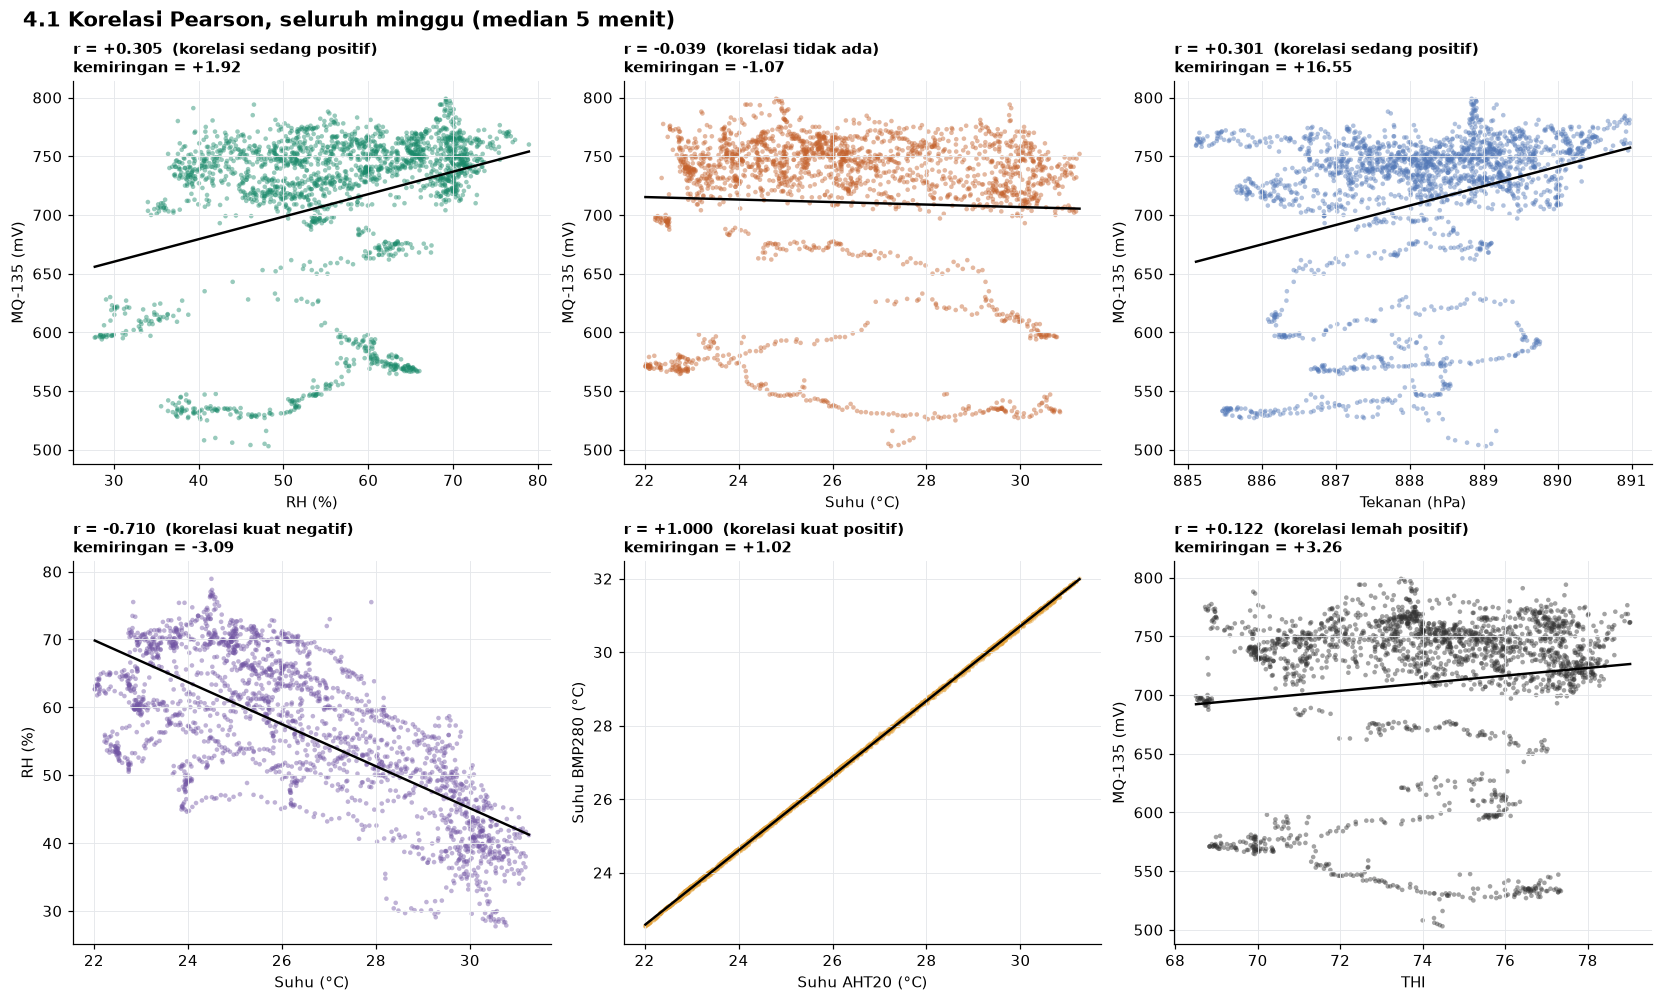

In [8]:
def strength(r):
    a = abs(r)
    lvl = 'tidak ada' if a < .1 else 'lemah' if a < .3 else 'sedang' if a < .5 else 'kuat'
    arah = '' if a < .1 else (' positif' if r > 0 else ' negatif')
    return f'korelasi {lvl}{arah}'

def scatter_r(ax, x, y, xl, yl, color):
    ok = x.notna() & y.notna(); x, y = x[ok], y[ok]
    r = np.corrcoef(x, y)[0, 1]
    m, c = np.polyfit(x, y, 1)
    ax.scatter(x, y, s=9, color=color, alpha=.45, edgecolors='none')
    xs = np.linspace(x.min(), x.max(), 50); ax.plot(xs, m * xs + c, color='black', lw=1.6)
    ax.set_xlabel(xl); ax.set_ylabel(yl)
    ax.set_title(f'r = {r:+.3f}  ({strength(r)})\nkemiringan = {m:+.2f}', loc='left', fontsize=10)
    ax.grid(True, color='#e5e7eb', lw=.6)
    return r

pairs = [('rh', 'mq', 'RH (%)', 'MQ-135 (mV)', '#1b8a6b'),
         ('temp', 'mq', 'Suhu (°C)', 'MQ-135 (mV)', '#c4622d'),
         ('press', 'mq', 'Tekanan (hPa)', 'MQ-135 (mV)', '#5278b7'),
         ('temp', 'rh', 'Suhu (°C)', 'RH (%)', '#7256a4'),
         ('temp', 'temp_bmp', 'Suhu AHT20 (°C)', 'Suhu BMP280 (°C)', '#e4a33c'),
         ('thi', 'mq', 'THI', 'MQ-135 (mV)', '#333333')]
fig, axs = plt.subplots(2, 3, figsize=(15, 9), layout='constrained')
for ax, (xk, yk, xl, yl, col) in zip(axs.ravel(), pairs):
    scatter_r(ax, b[xk], b[yk], xl, yl, col)
fig.suptitle('4.1 Korelasi Pearson, seluruh minggu (median 5 menit)', x=.01, ha='left', fontsize=14, fontweight='bold')
plt.show()

### 4.2 Matriks korelasi

Kiri: korelasi seluruh minggu. Tengah: korelasi **dalam hari yang sama** (rata-rata setiap hari dikurangkan dulu, sehingga perbedaan antarhari hilang). Kanan: korelasi **selisih 30 menit**, yang paling sedikit terpengaruh siklus harian.

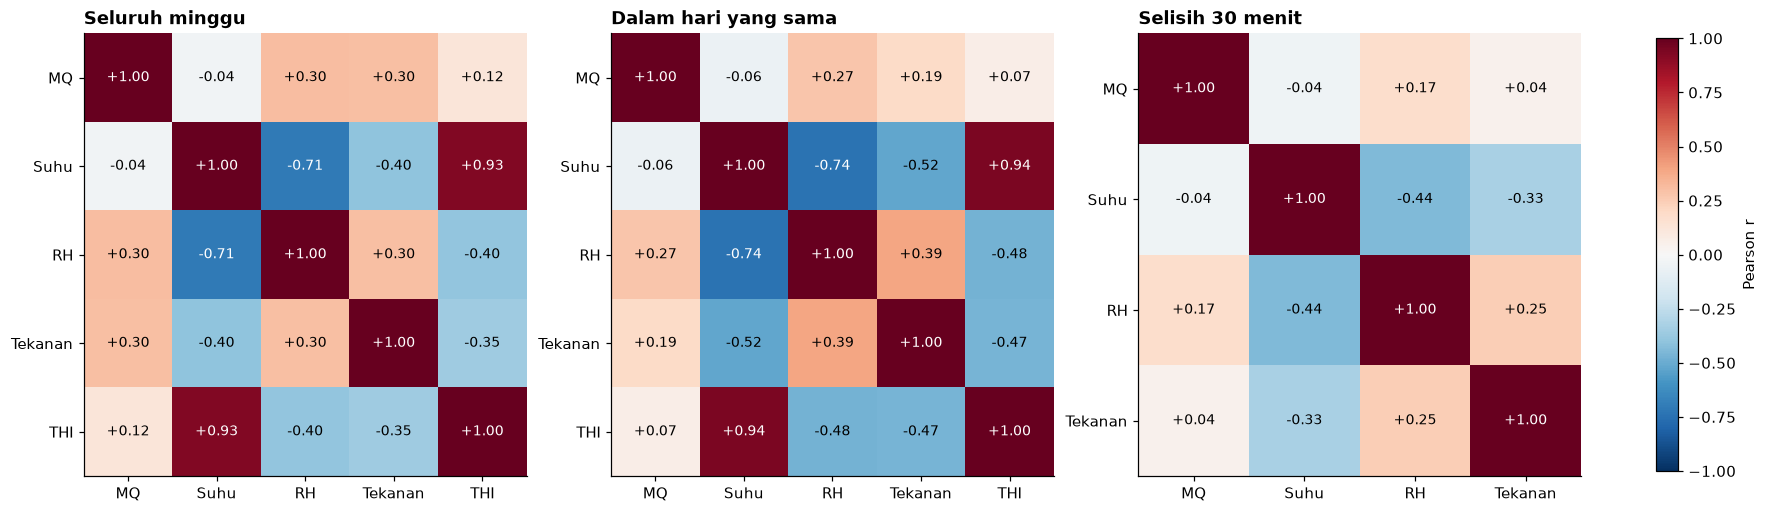

In [9]:
VARS = ['mq', 'temp', 'rh', 'press', 'thi']
LABELS = ['MQ', 'Suhu', 'RH', 'Tekanan', 'THI']
dc = b[VARS] - b.groupby('date')[VARS].transform('mean')
m1 = df.set_index('t')[['mq', 'temp', 'rh', 'press']].resample('1min').median()
d30 = m1.resample('30min').median().diff().dropna()
d30['thi'] = np.nan  # THI tidak dihitung untuk selisih
mats = [b[VARS].corr(), dc[VARS].corr(), d30[['mq', 'temp', 'rh', 'press']].corr()]
titles = ['Seluruh minggu', 'Dalam hari yang sama', 'Selisih 30 menit']
fig, axs = plt.subplots(1, 3, figsize=(16, 5), layout='constrained')
for ax, M, t in zip(axs, mats, titles):
    im = ax.imshow(M.values, cmap='RdBu_r', vmin=-1, vmax=1)
    lab = [LABELS[VARS.index(c)] for c in M.columns]
    ax.set_xticks(range(len(lab)), lab); ax.set_yticks(range(len(lab)), lab)
    for i in range(len(lab)):
        for j in range(len(lab)):
            v = M.values[i, j]
            ax.text(j, i, f'{v:+.2f}', ha='center', va='center', fontsize=9, color='white' if abs(v) > .6 else 'black')
    ax.set_title(t, loc='left')
fig.colorbar(im, ax=axs, shrink=.8, label='Pearson r')
plt.show()

### 4.3 Selisih 30 menit dengan uji permutasi

Untuk setiap setengah jam dihitung perubahan MQ, RH, dan suhu terhadap setengah jam sebelumnya. Signifikansi dihitung dengan **uji permutasi geser-sirkular**: deret RH (atau suhu) digeser minimal 6 jam sebanyak 5.000 kali, lalu p-value adalah proporsi geseran yang menghasilkan |*r*| sebesar atau lebih besar dari *r* asli. Cara ini mempertahankan struktur deret waktu, sehingga tidak terlalu optimistis seperti p-value biasa.

rh   : r = +0.175, p = 0.0002
temp : r = -0.044, p = 0.3467


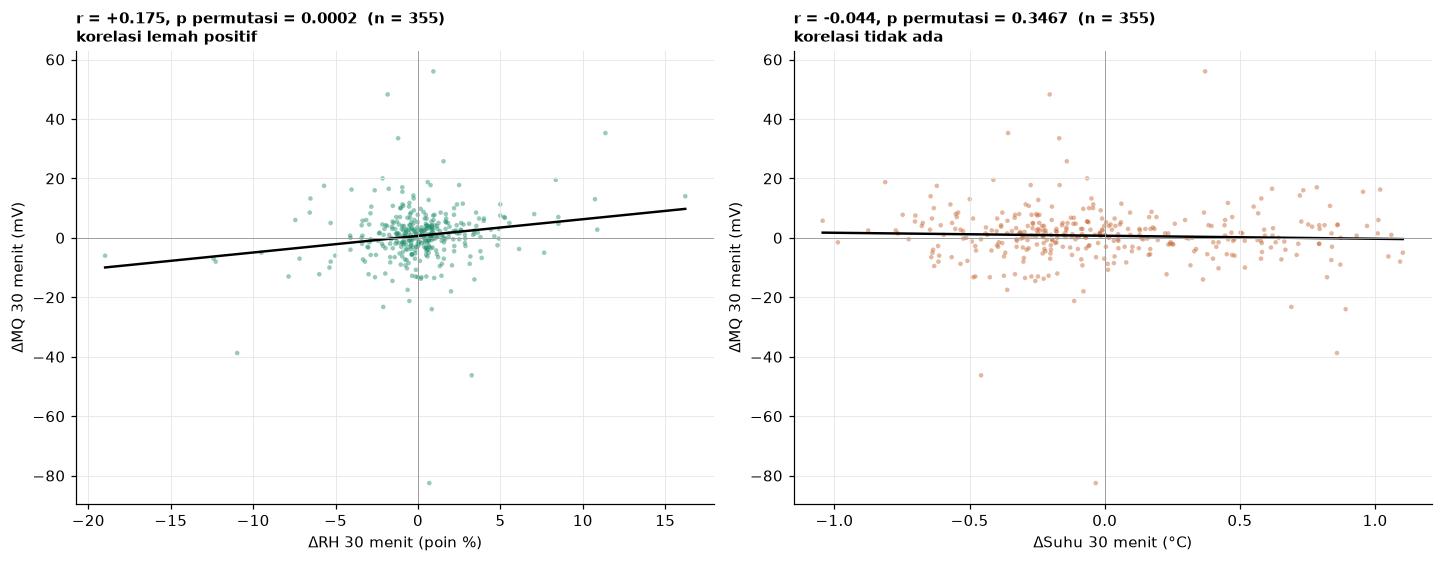

In [10]:
rng = np.random.default_rng(20261110)
def perm_p(a, c, n=5000, min_shift=12):     # 12 x 30 menit = 6 jam
    r0 = np.corrcoef(a, c)[0, 1]
    shifts = rng.integers(min_shift, len(a) - min_shift, n)
    null = np.array([np.corrcoef(a, np.roll(c, s))[0, 1] for s in shifts])
    return r0, ((np.abs(null) >= abs(r0)).sum() + 1) / (n + 1)

fig, axs = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
for ax, (k, xl, col) in zip(axs, [('rh', 'ΔRH 30 menit (poin %)', '#1b8a6b'), ('temp', 'ΔSuhu 30 menit (°C)', '#c4622d')]):
    r, p = perm_p(d30.mq.values, d30[k].values)
    scatter_r(ax, d30[k], d30.mq, xl, 'ΔMQ 30 menit (mV)', col)
    ax.set_title(f'r = {r:+.3f}, p permutasi = {p:.4f}  (n = {len(d30)})\n{strength(r)}', loc='left', fontsize=10)
    ax.axhline(0, color='#999', lw=.6); ax.axvline(0, color='#999', lw=.6)
    print(f'{k:5s}: r = {r:+.3f}, p = {p:.4f}')
plt.show()

### 4.4 Korelasi per hari (uji tanda)

Korelasi MQ–RH dan MQ–suhu dihitung terpisah untuk setiap hari. Jika RH memang memengaruhi MQ, korelasinya seharusnya positif hampir setiap hari. Uji tanda binomial menguji apakah jumlah hari positif lebih banyak dari yang diharapkan secara kebetulan (50:50).

RH: positif 8 dari 8 hari, p uji tanda = 0.008
Suhu: positif 2 dari 8 hari, p uji tanda = 0.289


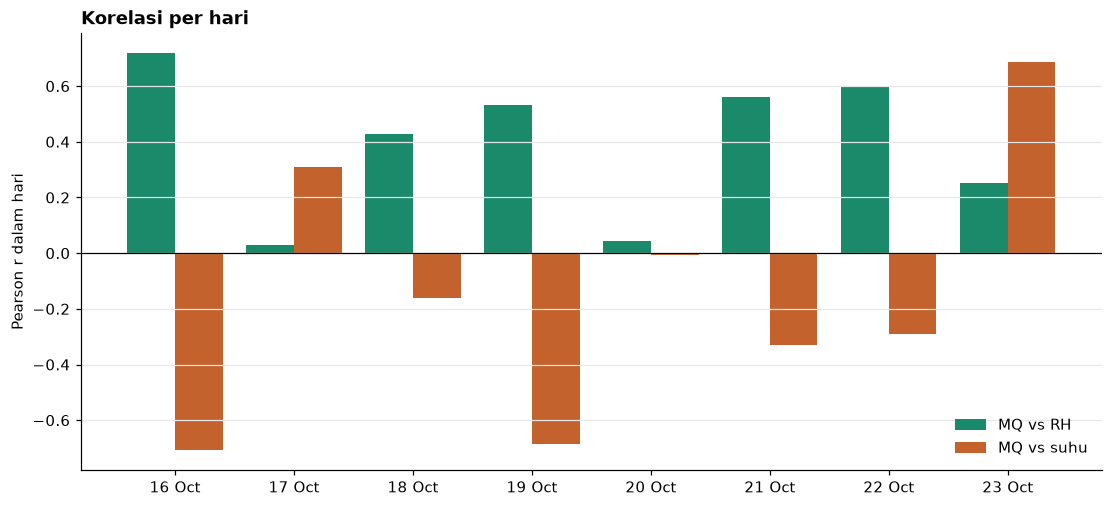

In [11]:
from math import comb
def sign_test(k, n):
    p = sum(comb(n, i) for i in range(n + 1) if comb(n, i) <= comb(n, k)) / 2 ** n
    return min(1.0, p)

daily = pd.DataFrame({v: {d: np.corrcoef(gr.mq, gr[v])[0, 1] for d, gr in b.groupby('date')} for v in ['rh', 'temp']})
fig, ax = plt.subplots(figsize=(10, 4.5), layout='constrained')
x = np.arange(len(daily))
ax.bar(x - .2, daily.rh, .4, color='#1b8a6b', label='MQ vs RH')
ax.bar(x + .2, daily.temp, .4, color='#c4622d', label='MQ vs suhu')
ax.axhline(0, color='black', lw=.8)
ax.set_xticks(x, [pd.Timestamp(d).strftime('%d %b') for d in daily.index]); ax.set_ylabel('Pearson r dalam hari')
ax.legend(frameon=False); ax.grid(True, axis='y', color='#e5e7eb')
for v, name in [('rh', 'RH'), ('temp', 'Suhu')]:
    k = int((daily[v] > 0).sum())
    print(f'{name}: positif {k} dari {len(daily)} hari, p uji tanda = {sign_test(k, len(daily)):.3f}')
ax.set_title('Korelasi per hari', loc='left')
plt.show()

## 5. Plot 3 dimensi

Plot 3D menampilkan tiga variabel sekaligus: suhu (sumbu X), RH (sumbu Y), dan respons MQ-135 (sumbu Z).

- **5.1** setiap bola adalah satu median 5 menit; warna dan ukuran bola mengikuti nilai MQ.
- **5.2** titik yang sama, diwarnai menurut status hasil *clustering* (Normal, Elevated, High).
- **5.3** bidang regresi berganda MQ = b₀ + b₁·Suhu + b₂·RH, yang memisahkan efek suhu dari efek RH.
- **5.4** permukaan rata-rata MQ untuk setiap kotak suhu × RH.

Agar tidak terlalu padat, plot 3D memakai median 30 menit (sekitar 350 titik). Periode awal pemanasan sensor (sebelum 18 Oktober) dibuang karena nilainya masih naik terus tanpa kaitan dengan suhu/RH.

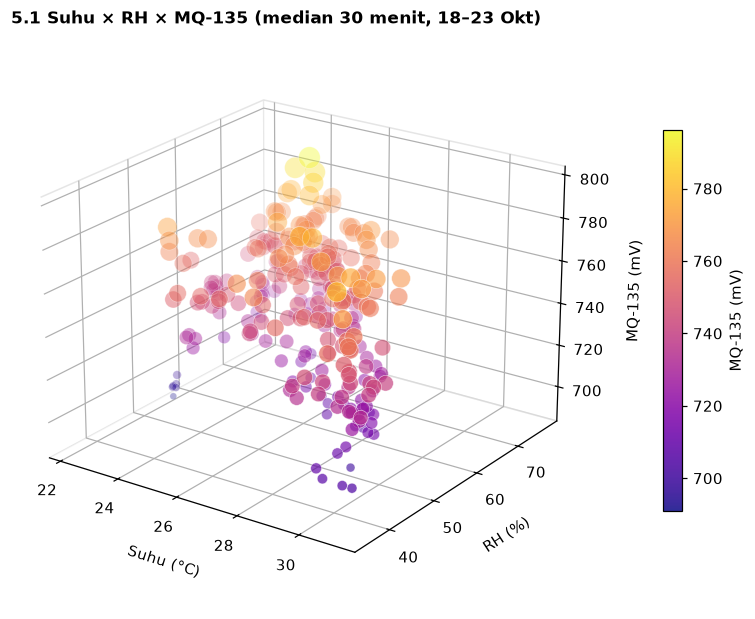

In [12]:
settled = b[b.index >= pd.Timestamp('2026-10-18', tz=TZ)]
s30 = settled[['mq', 'temp', 'rh']].resample('30min').median().dropna()

def style3d(ax, title):
    ax.set_xlabel('Suhu (°C)', labelpad=8); ax.set_ylabel('RH (%)', labelpad=8); ax.set_zlabel('MQ-135 (mV)', labelpad=8)
    ax.set_title(title, loc='left', fontsize=11, fontweight='bold')
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.pane.set_facecolor((1, 1, 1, 0)); axis.pane.set_edgecolor('#cccccc')
    ax.view_init(elev=22, azim=-55)

fig = plt.figure(figsize=(9, 7.5))
ax = fig.add_subplot(projection='3d')
size = 20 + 180 * (s30.mq - s30.mq.min()) / (s30.mq.max() - s30.mq.min())
sc = ax.scatter(s30.temp, s30.rh, s30.mq, c=s30.mq, s=size, cmap='plasma', alpha=.85,
                edgecolors='white', linewidths=.4, depthshade=True)
fig.colorbar(sc, ax=ax, shrink=.6, pad=.1, label='MQ-135 (mV)')
style3d(ax, '5.1 Suhu × RH × MQ-135 (median 30 menit, 18–23 Okt)')
plt.show()

Pusat cluster (mV): [716.5 742.3 765.1]  | batas: [729.4 753.7]


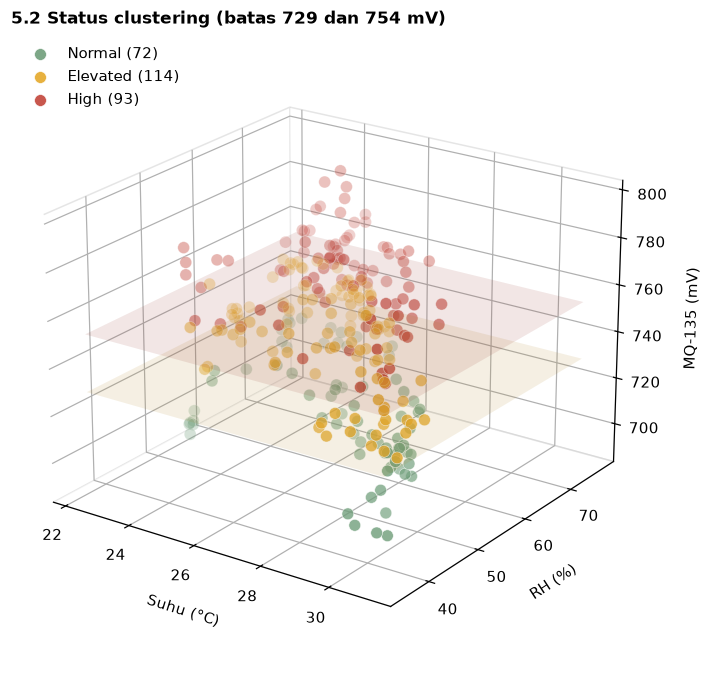

In [13]:
from sklearn.cluster import KMeans
km = KMeans(3, n_init=20, random_state=0).fit(settled[['mq']].values)
centres = np.sort(km.cluster_centers_.ravel())
bounds = (centres[:-1] + centres[1:]) / 2
print('Pusat cluster (mV):', centres.round(1), ' | batas:', bounds.round(1))

state_names = np.array(['Normal', 'Elevated', 'High'])
state_cols = {'Normal': '#6f9e7a', 'Elevated': '#e5a92a', 'High': '#c2453a'}
s30['state'] = state_names[np.digitize(s30.mq, bounds)]

fig = plt.figure(figsize=(9, 7.5))
ax = fig.add_subplot(projection='3d')
for st in state_names:
    q = s30[s30.state == st]
    ax.scatter(q.temp, q.rh, q.mq, s=60, color=state_cols[st], label=f'{st} ({len(q)})',
               edgecolors='white', linewidths=.4, alpha=.9, depthshade=True)
# bidang ambang peringatan
tt, hh = np.meshgrid(np.linspace(s30.temp.min(), s30.temp.max(), 2), np.linspace(s30.rh.min(), s30.rh.max(), 2))
for bd, col in zip(bounds, ['#e5a92a', '#c2453a']):
    ax.plot_surface(tt, hh, np.full_like(tt, bd), color=col, alpha=.12, edgecolor='none')
ax.legend(frameon=False, loc='upper left')
style3d(ax, f'5.2 Status clustering (batas {bounds[0]:.0f} dan {bounds[1]:.0f} mV)')
plt.show()

MQ = 688.8 +0.70·Suhu +0.63·RH   (R² = 0.077, n = 279)
Catatan: ini regresi pada median 30 menit seluruh periode 18–23 Okt. Analisis utama (laporan 10 Nov)
memakai regresi dalam-hari dengan interval kepercayaan bootstrap per hari.


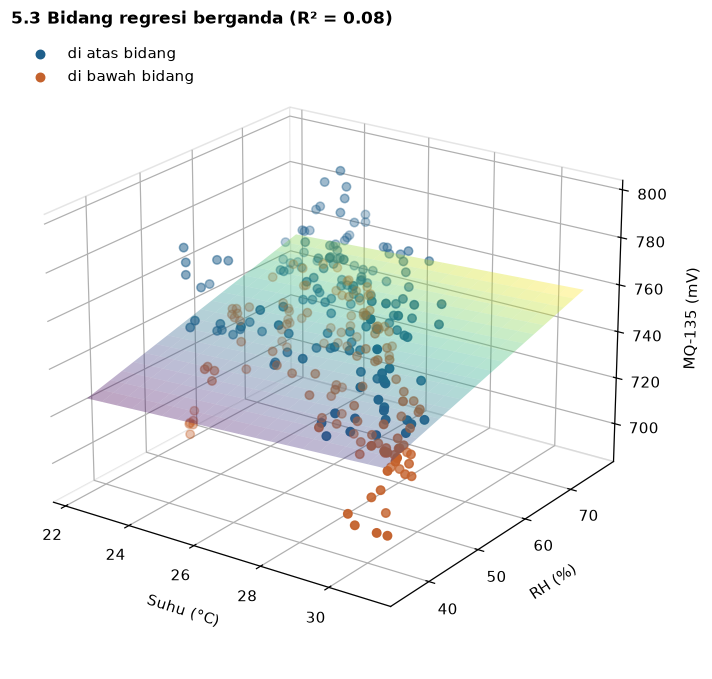

In [14]:
X = np.column_stack([np.ones(len(s30)), s30.temp, s30.rh])
beta, *_ = np.linalg.lstsq(X, s30.mq.values, rcond=None)
pred = X @ beta
r2 = 1 - ((s30.mq - pred) ** 2).sum() / ((s30.mq - s30.mq.mean()) ** 2).sum()
print(f'MQ = {beta[0]:.1f} {beta[1]:+.2f}·Suhu {beta[2]:+.2f}·RH   (R² = {r2:.3f}, n = {len(s30)})')
print('Catatan: ini regresi pada median 30 menit seluruh periode 18–23 Okt. Analisis utama (laporan 10 Nov)')
print('memakai regresi dalam-hari dengan interval kepercayaan bootstrap per hari.')

fig = plt.figure(figsize=(9, 7.5))
ax = fig.add_subplot(projection='3d')
tg, hg = np.meshgrid(np.linspace(s30.temp.min(), s30.temp.max(), 20), np.linspace(s30.rh.min(), s30.rh.max(), 20))
ax.plot_surface(tg, hg, beta[0] + beta[1] * tg + beta[2] * hg, cmap='viridis', alpha=.35, edgecolor='none')
above = s30.mq >= pred
ax.scatter(s30.temp[above], s30.rh[above], s30.mq[above], s=30, color='#1f5f8b', label='di atas bidang', depthshade=True)
ax.scatter(s30.temp[~above], s30.rh[~above], s30.mq[~above], s=30, color='#c4622d', label='di bawah bidang', depthshade=True)
ax.legend(frameon=False, loc='upper left')
style3d(ax, f'5.3 Bidang regresi berganda (R² = {r2:.2f})')
plt.show()

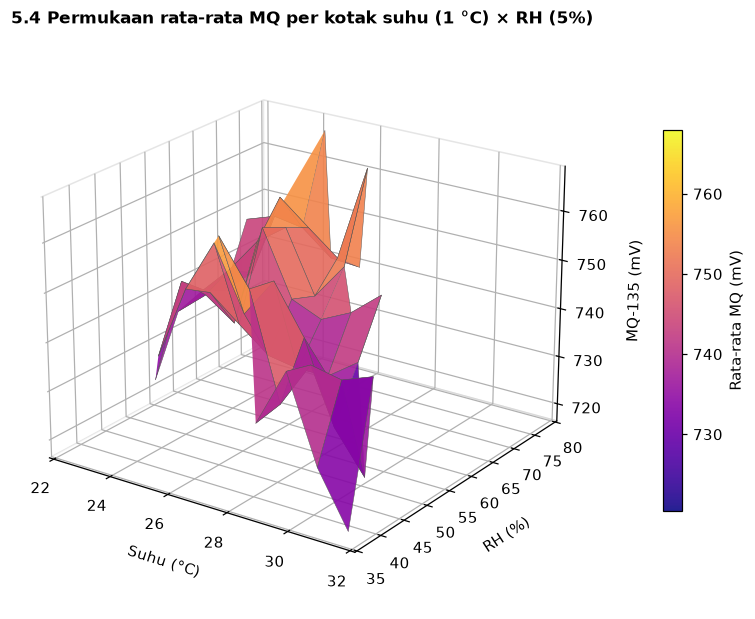

In [15]:
grid = settled.assign(tb=np.floor(settled.temp), hb=(np.floor(settled.rh / 5) * 5))
pivot = grid.groupby(['tb', 'hb']).mq.agg(['mean', 'count']).reset_index()
pivot = pivot[pivot['count'] >= 5]
P = pivot.pivot(index='hb', columns='tb', values='mean')
T, H = np.meshgrid(P.columns.values + .5, P.index.values + 2.5)
Z = np.ma.masked_invalid(P.values)

fig = plt.figure(figsize=(9, 7.5))
ax = fig.add_subplot(projection='3d')
surf = ax.plot_surface(T, H, Z, cmap='plasma', edgecolor='#555', linewidth=.3, alpha=.9)
fig.colorbar(surf, ax=ax, shrink=.6, pad=.1, label='Rata-rata MQ (mV)')
style3d(ax, '5.4 Permukaan rata-rata MQ per kotak suhu (1 °C) × RH (5%)')
plt.show()

## 6. Ambang peringatan dari clustering

Ambang dipilih dengan **k-means 1 dimensi** pada median 5 menit periode stabil (18–23 Okt), k = 3. Batas antarstatus adalah titik tengah antara dua pusat cluster (**centroid**) yang berdekatan. Batas inilah yang disebut **threshold centroid**.

Isi bagian ini:
- **6.1** arti centroid dan rumus threshold centroid;
- **6.2** langkah 1: k = 2 pada seluruh minggu, untuk menentukan mulai kapan data dianggap stabil;
- **6.3** langkah 2: k = 3 pada periode stabil, berisi tabel centroid dan perhitungan threshold;
- **6.4** cara k-means menemukan centroid (iterasi per langkah) dan pemeriksaan bahwa hasilnya optimal;
- **6.5** pemilihan jumlah cluster (*silhouette score*) dan persentase waktu di atas setiap ambang.

### 6.1 Centroid dan threshold centroid

**Centroid** (pusat cluster) adalah **rata-rata** semua titik dalam satu cluster. Di sini setiap titik adalah satu median 5 menit MQ-135, jadi centroid adalah nilai MQ rata-rata satu kelompok, dalam mV.

K-means (algoritma Lloyd) mencari centroid dengan empat langkah:
1. Pilih k centroid awal (tebakan).
2. Masukkan setiap titik ke cluster yang centroid-nya **paling dekat**.
3. Hitung ulang setiap centroid sebagai rata-rata anggotanya.
4. Ulangi langkah 2–3 sampai centroid tidak berubah lagi.

Yang dibuat sekecil mungkin adalah jumlah kuadrat jarak setiap titik ke centroid-nya (WCSS, *within-cluster sum of squares*):

$$\text{WCSS} = \sum_{j=1}^{k} \; \sum_{x \in C_j} (x - c_j)^2$$

**Dari centroid ke threshold.** Setiap titik masuk ke centroid terdekat, jadi batas antara dua cluster yang bersebelahan adalah nilai yang jaraknya **sama** ke kedua centroid. Untuk centroid yang diurutkan c₁ < c₂ < c₃:

$$|x - c_1| = |x - c_2| \;\Rightarrow\; T_1 = \frac{c_1 + c_2}{2}, \qquad T_2 = \frac{c_2 + c_3}{2}$$

Jadi **threshold centroid = titik tengah dua centroid yang berdekatan**. Karena clustering hanya memakai satu variabel (MQ), setiap batas berupa satu angka mV.

Status sebuah median 5 menit kemudian ditentukan dengan aturan berikut:

| Status | Aturan |
|---|---|
| Normal | MQ < T₁ |
| Elevated | T₁ ≤ MQ < T₂ |
| High | MQ ≥ T₂ |

Clustering dilakukan dalam dua langkah, sama dengan laporan 10 November:
- **Langkah 1 (6.2):** k = 2 pada seluruh minggu, untuk memisahkan masa pemanasan sensor dari periode stabil.
- **Langkah 2 (6.3):** k = 3 pada periode stabil, menghasilkan status Normal, Elevated dan High.

### 6.2 Langkah 1: k = 2 pada seluruh minggu

Pada awal pemakaian, respons MQ-135 masih naik terus (masa pemanasan sensor). Data itu tidak boleh ikut menentukan ambang. K-means k = 2 pada **semua** 2.128 median 5 menit memisahkan masa pemanasan dari sisa minggu. Periode stabil dimulai **tengah malam pertama setelah median 5 menit terakhir yang berada di bawah threshold** T₀.

Centroid c₁ (masa pemanasan)    = 571.4 mV  (374 median 5 menit)
Centroid c₂ (setelah pemanasan) = 740.2 mV  (1,754 median 5 menit)
Threshold T₀ = (571.4 + 740.2) / 2 = 655.8 mV   (silhouette k = 2: 0.81)
Median 5 menit terakhir di bawah T₀ : 17 Oct 2026 17:30 WIB
Awal periode stabil (tengah malam berikutnya): 18 Oct 2026 00:00 WIB
Awal data `settled` yang dipakai di bagian 5 dan 6: 18 Oct 2026 00:00 WIB


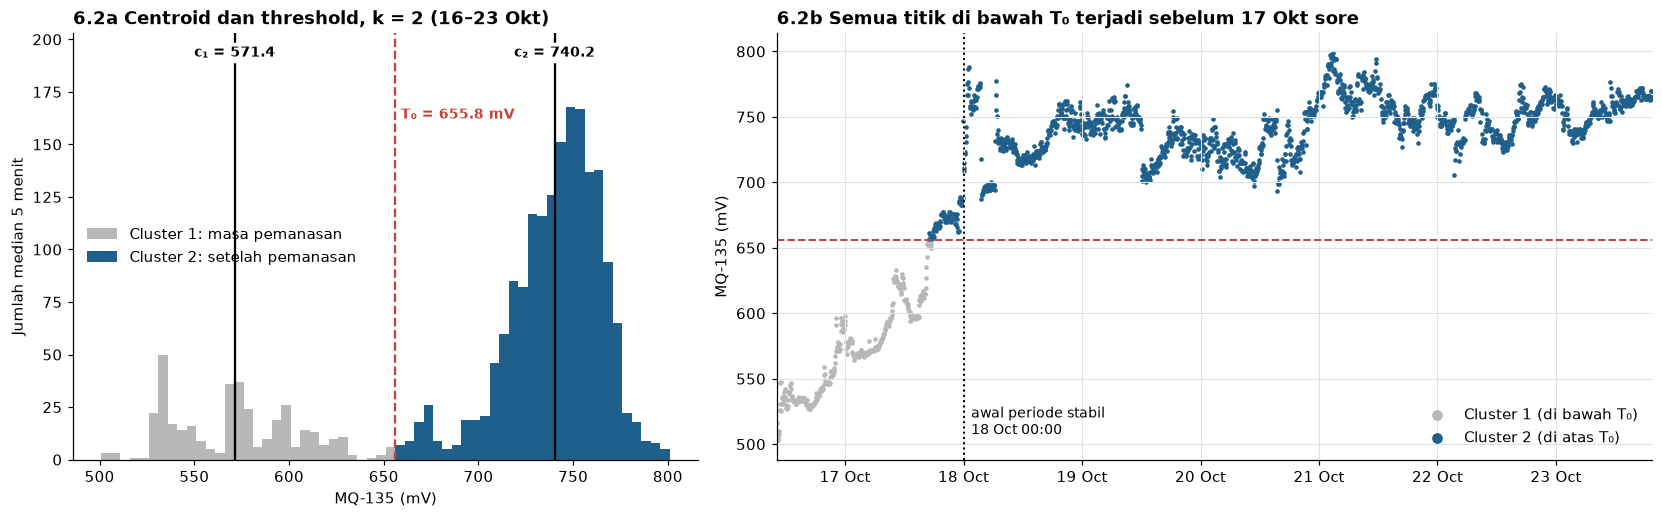

In [16]:
from sklearn.metrics import silhouette_score

km2 = KMeans(2, n_init=20, random_state=0).fit(b[['mq']].values)
c_minggu = np.sort(km2.cluster_centers_.ravel())
T0 = (c_minggu[0] + c_minggu[1]) / 2
atas_T0 = (b.mq >= T0).values
sil_k2 = silhouette_score(b[['mq']].values, atas_T0.astype(int))
terakhir_bawah = b.index[~atas_T0].max()
mulai_stabil = terakhir_bawah.floor('D') + pd.Timedelta(days=1)

print(f'Centroid c₁ (masa pemanasan)    = {c_minggu[0]:.1f} mV  ({(~atas_T0).sum():,} median 5 menit)')
print(f'Centroid c₂ (setelah pemanasan) = {c_minggu[1]:.1f} mV  ({atas_T0.sum():,} median 5 menit)')
print(f'Threshold T₀ = ({c_minggu[0]:.1f} + {c_minggu[1]:.1f}) / 2 = {T0:.1f} mV   (silhouette k = 2: {sil_k2:.2f})')
print(f'Median 5 menit terakhir di bawah T₀ : {terakhir_bawah:%d %b %Y %H:%M} WIB')
print(f'Awal periode stabil (tengah malam berikutnya): {mulai_stabil:%d %b %Y %H:%M} WIB')
print(f'Awal data `settled` yang dipakai di bagian 5 dan 6: {settled.index.min():%d %b %Y %H:%M} WIB')

fig, axs = plt.subplots(1, 2, figsize=(15, 4.6), layout='constrained', gridspec_kw={'width_ratios': [1, 1.4]})
ax = axs[0]
# tepi bin diletakkan tepat di celah T₀, supaya tidak ada batang yang berisi dua cluster
celah0 = (b.mq[~atas_T0].max() + b.mq[atas_T0].min()) / 2
bins_w = celah0 + 5 * np.arange(np.floor((b.mq.min() - celah0) / 5), np.ceil((b.mq.max() - celah0) / 5) + 1)
ax.hist([b.mq[~atas_T0], b.mq[atas_T0]], bins=bins_w, stacked=True, color=['#b8b8b8', '#1f5f8b'],
        label=['Cluster 1: masa pemanasan', 'Cluster 2: setelah pemanasan'])
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
for c, nm in zip(c_minggu, ['c₁', 'c₂']):
    ax.axvline(c, color='black', lw=1.5)
    ax.annotate(f'{nm} = {c:.1f}', (c, .97), xycoords=('data', 'axes fraction'), ha='center', va='top',
                fontsize=9, fontweight='bold', bbox=dict(boxstyle='round,pad=.25', fc='white', ec='none'))
ax.axvline(T0, color='#c2453a', ls='--', lw=1.5)
ax.annotate(f'T₀ = {T0:.1f} mV', (T0, .80), xycoords=('data', 'axes fraction'), xytext=(4, 0),
            textcoords='offset points', color='#c2453a', fontsize=9, fontweight='bold')
ax.set_xlabel('MQ-135 (mV)'); ax.set_ylabel('Jumlah median 5 menit'); ax.legend(frameon=False, loc='center left')
ax.set_title('6.2a Centroid dan threshold, k = 2 (16–23 Okt)', loc='left')

ax = axs[1]
ax.scatter(b.index[~atas_T0], b.mq[~atas_T0], s=4, color='#b8b8b8', label='Cluster 1 (di bawah T₀)')
ax.scatter(b.index[atas_T0], b.mq[atas_T0], s=4, color='#1f5f8b', label='Cluster 2 (di atas T₀)')
ax.axhline(T0, color='#c2453a', ls='--', lw=1.3)
ax.axvline(mulai_stabil, color='black', ls=':', lw=1.3)
ax.annotate(f'awal periode stabil\n{mulai_stabil:%d %b %H:%M}', (mulai_stabil, .06), xycoords=('data', 'axes fraction'),
            xytext=(5, 0), textcoords='offset points', fontsize=9)
time_axis(ax); ax.set_ylabel('MQ-135 (mV)'); ax.legend(frameon=False, loc='lower right', markerscale=3)
ax.set_title('6.2b Semua titik di bawah T₀ terjadi sebelum 17 Okt sore', loc='left')
plt.show()

**Hasil langkah 1.** Centroid kedua cluster adalah 571,4 mV dan 740,2 mV, jadi T₀ = (571,4 + 740,2) / 2 = 655,8 mV (sekitar 656 mV). Silhouette 0,81 berarti kedua kelompok ini benar-benar terpisah. Median 5 menit terakhir di bawah T₀ terjadi pada 17 Okt 17:30, sehingga periode stabil dimulai **18 Okt 00:00**. Inilah asal tanggal awal data `settled` di bagian 5 dan 6.

### 6.3 Langkah 2: k = 3 pada periode stabil (centroid → threshold)

K-means k = 3 dijalankan pada 1.674 median 5 menit periode stabil (18–23 Okt). Pusat cluster (`centres`) dan batasnya (`bounds`) sudah dihitung di sel 5.2. Sel berikut menampilkan centroid setiap status, lalu menghitung threshold dari centroid tersebut.

In [17]:
mq_st = settled['mq'].values
lab_st = np.digitize(mq_st, bounds)            # 0 = Normal, 1 = Elevated, 2 = High
n_st = np.bincount(lab_st, minlength=3)

tabel_centroid = pd.DataFrame({
    'status': state_names,
    'centroid (mV)': centres.round(1),
    'n median 5 mnt': n_st,
    '% waktu 18–23 Okt': (100 * n_st / len(mq_st)).round(1),
    'min (mV)': [mq_st[lab_st == j].min() for j in range(3)],
    'max (mV)': [mq_st[lab_st == j].max() for j in range(3)],
    'simpangan baku (mV)': [round(mq_st[lab_st == j].std(), 1) for j in range(3)],
    'suhu rata-rata (°C)': [round(settled.temp.values[lab_st == j].mean(), 1) for j in range(3)],
    'RH rata-rata (%)': [round(settled.rh.values[lab_st == j].mean(), 1) for j in range(3)],
}).set_index('status')
display(tabel_centroid)

c_1, c_2, c_3 = centres
tabel_threshold = pd.DataFrame({
    'threshold': ['T₁: Normal → Elevated ("watch")', 'T₂: Elevated → High (peringatan)'],
    'rumus': ['(c₁ + c₂) / 2', '(c₂ + c₃) / 2'],
    'perhitungan': [f'({c_1:.1f} + {c_2:.1f}) / 2', f'({c_2:.1f} + {c_3:.1f}) / 2'],
    'hasil (mV)': bounds.round(1),
    'jarak ke kedua centroid (mV)': [round((c_2 - c_1) / 2, 1), round((c_3 - c_2) / 2, 1)],
    'dibulatkan (mV)': [int(round(v)) for v in bounds],
}).set_index('threshold')
tabel_threshold

,centroid (mV),n median 5 mnt,% waktu 18–23 Okt,min (mV),max (mV),simpangan baku (mV),suhu rata-rata (°C),RH rata-rata (%)
status,,,,,,,,
Normal,716.5,423,25.3,687.5,729.0,9.8,27.1,54.2
Elevated,742.3,686,41.0,729.5,753.5,6.9,26.2,57.5
High,765.1,565,33.8,754.0,799.0,9.0,26.1,60.3


,rumus,perhitungan,hasil (mV),jarak ke kedua centroid (mV),dibulatkan (mV)
threshold,,,,,
"T₁: Normal → Elevated (""watch"")",(c₁ + c₂) / 2,(716.5 + 742.3) / 2,729.4,12.9,729
T₂: Elevated → High (peringatan),(c₂ + c₃) / 2,(742.3 + 765.1) / 2,753.7,11.4,754


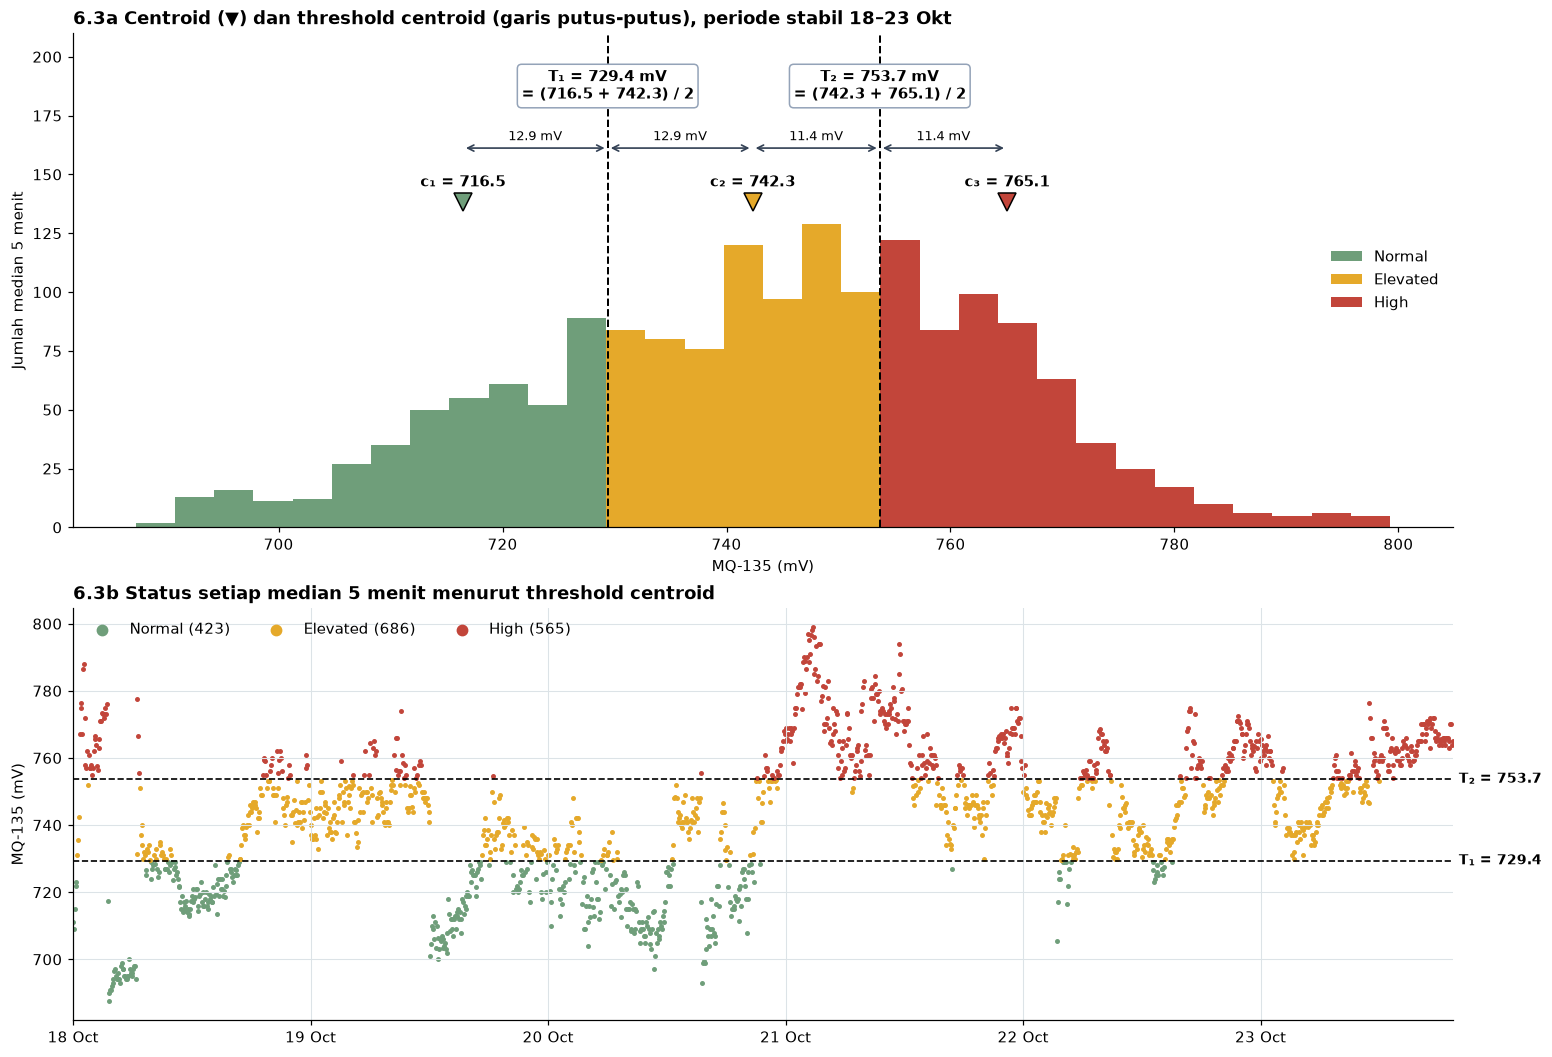

In [18]:
fig, axs = plt.subplots(2, 1, figsize=(14, 9.5), layout='constrained', gridspec_kw={'height_ratios': [1.2, 1]})
ax = axs[0]
# Lebar bin 3,5 mV (7 nilai median) dengan tepi di celah T₁ (729,0 | 729,5); tepi itu juga jatuh di celah T₂
# (753,5 | 754,0), jadi setiap batang hanya berisi satu status.
celah1 = (mq_st[lab_st == 0].max() + mq_st[lab_st == 1].min()) / 2
bins_c = celah1 + 3.5 * np.arange(np.floor((mq_st.min() - celah1) / 3.5), np.ceil((mq_st.max() - celah1) / 3.5) + 1)
ax.hist([mq_st[lab_st == j] for j in range(3)], bins=bins_c, stacked=True,
        color=[state_cols[s] for s in state_names], label=list(state_names))
top = ax.get_ylim()[1]
ax.set_ylim(0, top * 1.55)
sub = '₁₂₃'
for j, (c, s) in enumerate(zip(centres, state_names)):
    ax.plot([c], [top * 1.02], marker='v', ms=12, color=state_cols[s], mec='black', zorder=5)
    ax.annotate(f'c{sub[j]} = {c:.1f}', (c, top * 1.07), ha='center', fontsize=10, fontweight='bold')
for j, T in enumerate(bounds):
    ax.axvline(T, color='black', ls='--', lw=1.3)
    ca, cb = centres[j], centres[j + 1]
    y = top * 1.19
    for a, z in ((ca, T), (T, cb)):
        ax.annotate('', (a, y), (z, y), arrowprops=dict(arrowstyle='<->', color='#334155', lw=1.1))
        ax.text((a + z) / 2, y + top * .015, f'{(cb - ca) / 2:.1f} mV', ha='center', va='bottom', fontsize=8.5)
    ax.annotate(f'T{sub[j]} = {T:.1f} mV\n= ({ca:.1f} + {cb:.1f}) / 2', (T, top * 1.33), ha='center', va='bottom',
                fontsize=9.5, fontweight='bold', bbox=dict(boxstyle='round,pad=.3', fc='white', ec='#94a3b8'))
ax.set_xlabel('MQ-135 (mV)'); ax.set_ylabel('Jumlah median 5 menit'); ax.legend(frameon=False, loc='center right')
ax.set_title('6.3a Centroid (▼) dan threshold centroid (garis putus-putus), periode stabil 18–23 Okt', loc='left')

ax = axs[1]
for j, s in enumerate(state_names):
    m = lab_st == j
    ax.scatter(settled.index[m], mq_st[m], s=5, color=state_cols[s], label=f'{s} ({n_st[j]})')
for j, T in enumerate(bounds):
    ax.axhline(T, color='black', ls='--', lw=1.1)
    ax.annotate(f'T{sub[j]} = {T:.1f}', (1, T), xycoords=('axes fraction', 'data'), xytext=(4, 0),
                textcoords='offset points', va='center', fontsize=9, fontweight='bold')
time_axis(ax); ax.set_ylabel('MQ-135 (mV)'); ax.legend(frameon=False, loc='upper left', markerscale=3, ncol=3)
ax.set_title('6.3b Status setiap median 5 menit menurut threshold centroid', loc='left')
plt.show()

### Cara membaca tabel centroid dan threshold

**Tabel centroid.** Setiap baris adalah satu status hasil k-means.
- `centroid (mV)` adalah rata-rata MQ semua anggota status itu. Contoh: c₂ = 742,3 mV adalah rata-rata 686 median 5 menit berstatus Elevated.
- `min` dan `max` menunjukkan rentang setiap status, dan rentangnya **tidak tumpang tindih**: Normal 687,5–729,0 mV, Elevated 729,5–753,5 mV, High 754,0–799,0 mV. Median 5 menit selalu bernilai kelipatan 0,5 mV, jadi T₁ jatuh di celah antara 729,0 dan 729,5 mV, dan T₂ di celah antara 753,5 dan 754,0 mV.
- `% waktu` menunjukkan porsi periode stabil pada setiap status: Normal 25,3%, Elevated 41,0%, High 33,8%.
- Kolom suhu dan RH hanya **deskripsi**. Clustering hanya memakai MQ. RH rata-rata naik dari Normal ke High (54,2 → 57,5 → 60,3%), sejalan dengan temuan bagian 4 bahwa RH ikut menaikkan respons MQ.

**Tabel threshold.** Setiap threshold dihitung langsung dari dua centroid yang berdekatan:
- T₁ = (716,5 + 742,3) / 2 = **729,4 mV**. Jaraknya ke c₁ dan ke c₂ sama, yaitu 12,9 mV.
- T₂ = (742,3 + 765,1) / 2 = **753,7 mV**. Jaraknya ke c₂ dan ke c₃ sama, yaitu 11,4 mV.
- Dibulatkan menjadi **729 mV** (tingkat *watch*) dan **754 mV** (tingkat peringatan). Usulan peringatan dini dari laporan 10 November: median 5 menit ≥ 754 mV selama 30 menit.

Pada grafik 6.3a, panah di atas histogram menunjukkan bahwa setiap garis putus-putus berada tepat di tengah dua segitiga (centroid). Grafik 6.3b menunjukkan status setiap median 5 menit sepanjang 18–23 Okt. Status High lebih sering muncul mulai malam 20–21 Okt.

> Centroid dan threshold ini hanya berlaku untuk modul `mq135-01` dan masih berupa **usulan**. Nilai mV di sini adalah respons relatif, **bukan ppm amonia**. Modul `mq135-02` membaca sekitar 120–240 mV di meja uji, jadi centroid-nya harus dihitung ulang dari data modul itu sendiri.

### 6.4 Bagaimana k-means menemukan centroid

Sel berikut menulis ulang k-means secara manual (tanpa scikit-learn), supaya setiap langkah di 6.1 terlihat angkanya:
- **A.** satu kali jalan dari tebakan awal persentil 10, 50 dan 90, dengan tabel centroid, threshold, jumlah anggota dan WCSS di setiap iterasi;
- **B.** 20 tebakan awal acak, karena k-means bisa berhenti di **solusi lokal** yang bergantung pada tebakan awal. scikit-learn juga menjalankan 20 tebakan awal (`n_init=20`) dan memilih WCSS terkecil;
- **C.** pembanding: hasil manual, hasil scikit-learn yang dipakai di notebook, dan **pencarian menyeluruh**. Pada data 1 dimensi setiap cluster k-means berupa satu rentang nilai yang berurutan. Karena itu semua kemungkinan pasangan batas bisa dicoba satu per satu untuk mencari WCSS terkecil yang sesungguhnya (minimum global).

In [19]:
def kmeans_1d(x, c_awal, max_iter=100):
    # K-means (Lloyd) 1 dimensi, ditulis manual agar setiap langkah terlihat.
    c = np.sort(np.asarray(c_awal, dtype=float))                   # langkah 1: centroid awal
    rows = []
    for it in range(1, max_iter + 1):
        lab = np.argmin(np.abs(x[:, None] - c[None, :]), axis=1)    # langkah 2: titik -> centroid terdekat
        n = np.bincount(lab, minlength=len(c))
        rows.append({'iterasi': it, 'c₁': c[0], 'c₂': c[1], 'c₃': c[2],
                     'T₁': (c[0] + c[1]) / 2, 'T₂': (c[1] + c[2]) / 2,
                     'n₁': n[0], 'n₂': n[1], 'n₃': n[2], 'WCSS': ((x - c[lab]) ** 2).sum()})
        c_baru = np.array([x[lab == j].mean() for j in range(len(c))])  # langkah 3: centroid = rata-rata anggota
        if np.allclose(c_baru, c):                                      # langkah 4: berhenti jika tidak berubah
            break
        c = c_baru
    return c, pd.DataFrame(rows).set_index('iterasi')

c_awal = np.percentile(mq_st, [10, 50, 90])
c_demo, iterasi_demo = kmeans_1d(mq_st, c_awal)
print('A. Tebakan awal = persentil 10, 50, 90 dari MQ periode stabil:', c_awal.round(1), 'mV')
print(f'   Berhenti setelah {len(iterasi_demo)} iterasi (centroid tidak berubah lagi).')
iterasi_demo.round(2)

A. Tebakan awal = persentil 10, 50, 90 dari MQ periode stabil: [716. 745. 768.] mV
   Berhenti setelah 4 iterasi (centroid tidak berubah lagi).


,c₁,c₂,c₃,T₁,T₂,n₁,n₂,n₃,WCSS
iterasi,,,,,,,,,
1,716.00,745.00,768.00,730.50,756.50,451,756,467,122117.50
2,717.29,744.43,767.16,730.86,755.79,451,727,496,120396.57
3,717.29,743.96,766.51,730.63,755.24,451,721,502,119960.36
4,717.29,743.87,766.38,730.58,755.12,451,721,502,119945.03


In [20]:
rng = np.random.default_rng(0)
nilai_unik = np.unique(mq_st)
jalan = []
for r in range(20):
    c_fin, tr = kmeans_1d(mq_st, rng.choice(nilai_unik, 3, replace=False))
    jalan.append({'c₁': c_fin[0], 'c₂': c_fin[1], 'c₃': c_fin[2], 'T₁': (c_fin[0] + c_fin[1]) / 2,
                  'T₂': (c_fin[1] + c_fin[2]) / 2, 'WCSS': tr['WCSS'].iloc[-1]})
jalan = pd.DataFrame(jalan).round(2)
solusi = (jalan.groupby(list(jalan.columns)).size().rename('jumlah tebakan awal').reset_index()
          .sort_values('WCSS').reset_index(drop=True))
solusi.index = [f'solusi {i + 1}' for i in range(len(solusi))]
print(f'B. 20 tebakan awal acak berhenti di {len(solusi)} solusi berbeda '
      f'(T₁ {solusi["T₁"].min():.1f}–{solusi["T₁"].max():.1f} mV, T₂ {solusi["T₂"].min():.1f}–{solusi["T₂"].max():.1f} mV).')
solusi

B. 20 tebakan awal acak berhenti di 6 solusi berbeda (T₁ 728.4–732.1 mV, T₂ 752.8–756.2 mV).


,c₁,c₂,c₃,T₁,T₂,WCSS,jumlah tebakan awal
solusi 1,716.61,742.89,765.65,729.75,754.27,119714.72,1
solusi 2,716.61,742.42,765.05,729.51,753.74,119718.32,1
solusi 3,715.57,741.20,764.34,728.39,752.77,119915.56,7
solusi 4,717.29,743.87,766.38,730.58,755.12,119945.03,1
solusi 5,718.09,744.39,766.38,731.24,755.38,120073.22,2
solusi 6,718.81,745.35,767.04,732.08,756.20,120578.76,8


In [21]:
def kmeans_1d_menyeluruh(x):
    # Coba semua pasangan batas (k = 3) dan kembalikan WCSS terkecil. Cluster 1D selalu berupa rentang berurutan.
    u, cnt = np.unique(x, return_counts=True)
    N = np.r_[0, np.cumsum(cnt)]; S = np.r_[0, np.cumsum(cnt * u)]; Q = np.r_[0, np.cumsum(cnt * u * u)]
    def sse(a, z):                                   # jumlah kuadrat simpangan kelompok u[a:z]
        s = S[z] - S[a]
        return (Q[z] - Q[a]) - s * s / (N[z] - N[a])
    i, j = np.triu_indices(len(u), 1)
    i, j = i[i >= 1], j[i >= 1]
    w = sse(0, i) + sse(i, j) + sse(j, len(u))
    k = np.argmin(w); i, j = i[k], j[k]
    c = np.array([S[i] / N[i], (S[j] - S[i]) / (N[j] - N[i]), (S[-1] - S[j]) / (N[-1] - N[j])])
    return c, w[k], len(w), (u[i - 1], u[i]), (u[j - 1], u[j])

c_opt, wcss_opt, n_pasangan, celah1, celah2 = kmeans_1d_menyeluruh(mq_st)
terbaik = solusi.iloc[0]

def baris(nama, c, w):
    return {'metode': nama, 'c₁': c[0], 'c₂': c[1], 'c₃': c[2], 'T₁': (c[0] + c[1]) / 2, 'T₂': (c[1] + c[2]) / 2, 'WCSS': w}

banding = pd.DataFrame([
    baris('A. Manual, tebakan awal persentil', c_demo, iterasi_demo['WCSS'].iloc[-1]),
    baris('B. Manual, terbaik dari 20 tebakan acak', terbaik[['c₁', 'c₂', 'c₃']].values, terbaik['WCSS']),
    baris('scikit-learn KMeans (n_init=20), dipakai di notebook', centres, km.inertia_),
    baris('C. Pencarian menyeluruh (minimum global)', c_opt, wcss_opt),
]).set_index('metode').round(2)

lab_terdekat = np.argmin(np.abs(mq_st[:, None] - centres[None, :]), axis=1)
rata_anggota = np.array([mq_st[lab_st == j].mean() for j in range(3)])
print(f'C. Pencarian menyeluruh mencoba {n_pasangan:,} pasangan batas.')
print(f'   WCSS terkecil: batas di antara {celah1[0]} dan {celah1[1]} mV, serta di antara {celah2[0]} dan {celah2[1]} mV.')
print('Pemeriksaan:')
print(f'   Selisih centroid scikit-learn dan minimum global         : {np.abs(centres - c_opt).max():.6f} mV')
print(f'   Selisih centroid dan rata-rata anggotanya                : {np.abs(centres - rata_anggota).max():.6f} mV')
print(f'   Titik yang statusnya beda antara "centroid terdekat" dan aturan threshold: {int((lab_terdekat != lab_st).sum())} dari {len(mq_st):,}')
banding

C. Pencarian menyeluruh mencoba 17,391 pasangan batas.
   WCSS terkecil: batas di antara 729.0 dan 729.5 mV, serta di antara 753.5 dan 754.0 mV.
Pemeriksaan:
   Selisih centroid scikit-learn dan minimum global         : 0.000000 mV
   Selisih centroid dan rata-rata anggotanya                : 0.000000 mV
   Titik yang statusnya beda antara "centroid terdekat" dan aturan threshold: 0 dari 1,674


,c₁,c₂,c₃,T₁,T₂,WCSS
metode,,,,,,
"A. Manual, tebakan awal persentil",717.29,743.87,766.38,730.58,755.12,119945.03
"B. Manual, terbaik dari 20 tebakan acak",716.61,742.89,765.65,729.75,754.27,119714.72
"scikit-learn KMeans (n_init=20), dipakai di notebook",716.46,742.33,765.05,729.39,753.69,119705.87
C. Pencarian menyeluruh (minimum global),716.46,742.33,765.05,729.39,753.69,119705.87


### Cara membaca hasil 6.4

**Tabel A (iterasi).** Setiap baris adalah satu putaran langkah 2–3. Dari tebakan awal (716,0; 745,0; 768,0 mV), centroid bergeser dan WCSS turun di setiap putaran, sampai pada iterasi 4 tidak ada titik yang pindah cluster dan centroid berhenti berubah. Hasilnya T₁ = 730,6 mV dan T₂ = 755,1 mV.

**Tabel B (20 tebakan acak).** Tebakan awal yang berbeda bisa berhenti di solusi yang berbeda. Penyebabnya, data periode stabil membentuk satu sebaran kontinu tanpa celah yang jelas (lihat silhouette di 6.5), sehingga ada beberapa "lembah" WCSS yang hampir sama dalamnya. Namun semua solusi itu memberi threshold yang berdekatan: T₁ 728,4–732,1 mV dan T₂ 752,8–756,2 mV. Jadi pilihan tebakan awal hanya menggeser threshold sekitar ±2 mV.

**Tabel C (pembanding).** Ini bagian terpenting untuk menjawab "algoritma apa yang dipakai dan apakah hasilnya benar":
- scikit-learn (20 tebakan awal *k-means++*) menghasilkan WCSS **119.705,87**, lebih kecil dari semua hasil manual.
- Pencarian menyeluruh, yang mencoba setiap kemungkinan pasangan batas, memberi WCSS terkecil yang **sama persis** dan centroid yang sama (selisih 0,000000 mV). Artinya centroid 716,5 / 742,3 / 765,1 mV adalah **solusi optimal global** k-means k = 3 untuk data ini, bukan kebetulan dari tebakan awal.
- Centroid sama dengan rata-rata anggotanya (definisi centroid terpenuhi), dan aturan "masuk ke centroid terdekat" memberi status yang sama dengan aturan threshold untuk semua 1.674 titik. Jadi memakai threshold T₁ dan T₂ setara dengan menjalankan k-means itu sendiri.

### 6.5 Memilih jumlah cluster dan dampak setiap ambang

Jumlah cluster diperiksa dengan *silhouette score*: makin tinggi, makin terpisah kelompoknya. Tabel di bawah grafik menunjukkan berapa persen waktu periode stabil yang berada di atas setiap ambang.

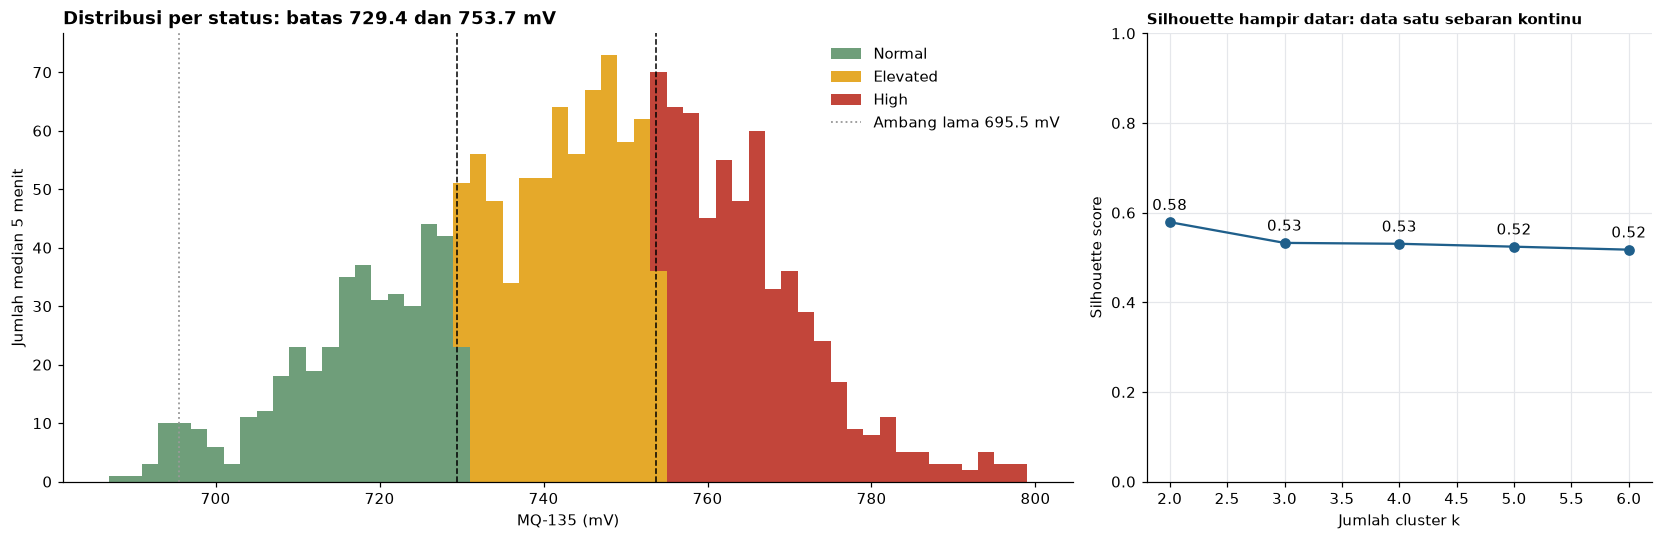

,Ambang,mV,% waktu di atas (18–23 Okt)
0,Ambang perangkat (lama),695.5,98.7
1,Watch (Normal/Elevated),729.4,74.7
2,Peringatan (Elevated/High),753.7,33.8


In [22]:
from sklearn.metrics import silhouette_score
Xs = settled[['mq']].values
ks, sil = range(2, 7), []
for k in ks:
    lab = KMeans(k, n_init=20, random_state=0).fit_predict(Xs)
    sil.append(silhouette_score(Xs, lab))

fig, axs = plt.subplots(1, 2, figsize=(15, 4.8), layout='constrained', gridspec_kw={'width_ratios': [2, 1]})
ax = axs[0]
binsv = np.arange(np.floor(settled.mq.min()), settled.mq.max() + 2, 2)
lab3 = state_names[np.digitize(settled.mq, bounds)]
ax.hist([settled.mq[lab3 == s] for s in state_names], bins=binsv, stacked=True,
        color=[state_cols[s] for s in state_names], label=list(state_names))
for bd in bounds: ax.axvline(bd, color='black', ls='--', lw=1)
ax.axvline(device_thr, color='#999', ls=':', lw=1.2, label=f'Ambang lama {device_thr:.1f} mV')
ax.set_xlabel('MQ-135 (mV)'); ax.set_ylabel('Jumlah median 5 menit'); ax.legend(frameon=False)
ax.set_title(f'Distribusi per status: batas {bounds[0]:.1f} dan {bounds[1]:.1f} mV', loc='left')
ax = axs[1]
ax.plot(list(ks), sil, 'o-', color='#1f5f8b'); ax.set_ylim(0, 1)
ax.set_xlabel('Jumlah cluster k'); ax.set_ylabel('Silhouette score'); ax.grid(True, color='#e5e7eb')
ax.set_title('Silhouette hampir datar: data satu sebaran kontinu', loc='left', fontsize=10)
for k, s in zip(ks, sil): ax.annotate(f'{s:.2f}', (k, s), textcoords='offset points', xytext=(0, 8), ha='center')
plt.show()

above = pd.DataFrame({'Ambang': ['Ambang perangkat (lama)', 'Watch (Normal/Elevated)', 'Peringatan (Elevated/High)'],
                      'mV': [round(device_thr, 1), round(bounds[0], 1), round(bounds[1], 1)]})
above['% waktu di atas (18–23 Okt)'] = [round(100 * (settled.mq >= v).mean(), 1) for v in above['mV']]
above

## 7. Dashboard interaktif (Gradio)

Sel pertama di bawah menyiapkan fungsi-fungsi plot untuk dashboard dan langsung menampilkan contoh hasilnya, jadi bisa diperiksa tanpa Gradio. Sel kedua membuat dashboard Gradio dan menjalankannya di dalam notebook.

Gradio perlu dipasang sekali di environment Jupyter:

```
pip install gradio
```

Isi dashboard:
- **Deret waktu**: pilih variabel dan rentang tanggal; batas dari jurnal digambar sebagai pita berwarna.
- **Jam kritis**: heatmap hari × jam untuk variabel pilihan, dengan kotak bergaris saat batas jurnal terlewati.
- **3D**: suhu × RH × MQ-135, diwarnai THI atau status MQ.
- **Insight**: ringkasan angka untuk rentang tanggal yang dipilih.

**Rentang:** 2026-10-16 sampai 2026-10-23 (177 jam data)

- Suhu di atas zona termonetral ayam petelur (> 22 °C) [R1]: **177.3 jam** (100% waktu). Suhu terendah 22.0 °C, tertinggi 31.3 °C pada 20 Oct 12:55 WIB.
- Jam yang paling sering masuk kategori bahaya THI: 10.00, 11.00, 12.00, 13.00, 14.00, 15.00, 16.00, 17.00, 18.00.
- THI kategori bahaya (≥ 75) [R3]: **74.8 jam**; THI maksimum 79.0.
- RH di atas 60%: **73.8 jam**, terutama malam hari.
- MQ-135 median 737 mV; di atas 754 mV selama 47.1 jam (relatif untuk modul ini, bukan ppm amonia).


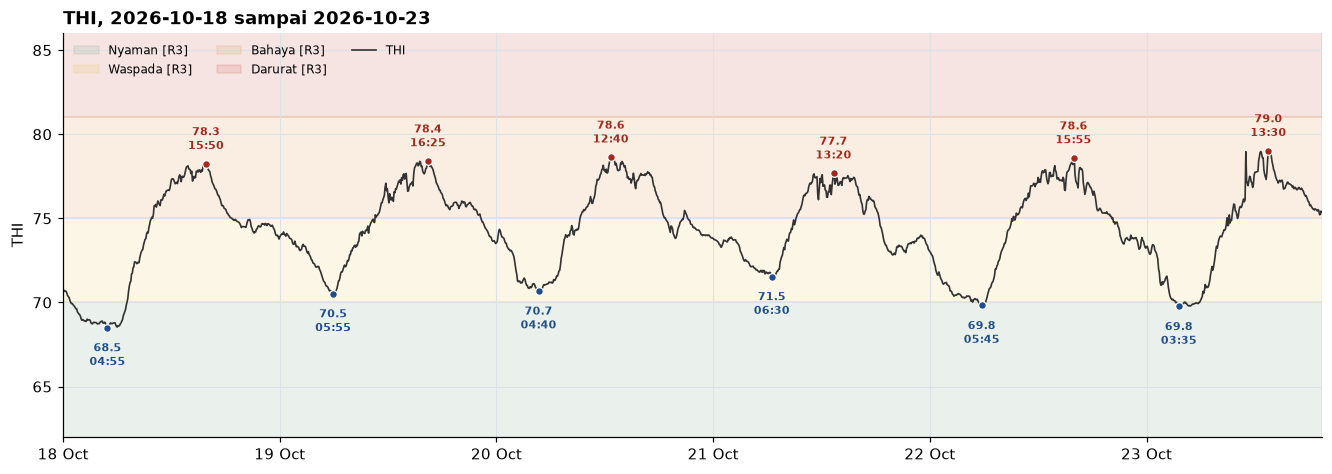

In [23]:
VAR_INFO = {
    'Suhu (°C)':        ('temp', '#d34c40', [(TN_LOW, TN_HIGH, '#6f9e7a', 'Zona termonetral ayam petelur 19–22 °C [R1]')], None),
    'RH (%)':           ('rh', '#168d9b', [(RH_LOW, RH_HIGH, '#168d9b', 'Pedoman 40–60% (penyuluhan)')], lambda v: v > RH_HIGH),
    'THI':              ('thi', '#333333', [(lo if np.isfinite(lo) else 60, hi if np.isfinite(hi) else 90, c, f'{n} [R3]') for lo, hi, n, c in THI_BANDS], lambda v: v >= 75),
    'MQ-135 (mV)':      ('mq', '#7256a4', [], None),
    'Tekanan (hPa)':    ('press', '#5278b7', [], None),
}
ALL_DAYS = sorted(b['date'].unique())

def _subset(start, end):
    s = pd.Timestamp(start, tz=TZ); e = pd.Timestamp(end, tz=TZ) + pd.Timedelta(days=1)
    return b[(b.index >= s) & (b.index < e)]

def fig_timeseries(var, start, end):
    col, color, bands, _ = VAR_INFO[var]
    d = _subset(start, end)
    fig, ax = plt.subplots(figsize=(12, 4.2), layout='constrained')
    for lo, hi, c, lab in bands:
        ax.axhspan(lo, hi, color=c, alpha=.14, label=lab)
    ax.plot(d.index, d[col], color=color, lw=1.1, label=var)
    mark_peaks_lows(ax, d[col], '', dp=0 if col == 'mq' else 1)
    if col == 'mq':
        ax.axhline(device_thr, color='#999', ls=':', label=f'Ambang perangkat {device_thr:.1f} (bukan jurnal)')
        for bd, c in zip(bounds, ['#e5a92a', '#c2453a']):
            ax.axhline(bd, color=c, ls='--', lw=1, label=f'{bd:.0f} mV (k-means, bukan jurnal)')
    if col == 'thi':
        ax.set_ylim(62, 86)
    time_axis(ax); ax.set_ylabel(var); ax.legend(frameon=False, fontsize=8, ncol=3, loc='upper left')
    ax.set_title(f'{var}, {start} sampai {end}', loc='left')
    return fig

def fig_dayhour(var):
    col, _, _, rule = VAR_INFO[var]
    M = day_hour(col)
    fig, ax = plt.subplots(figsize=(12, 4.2), layout='constrained')
    im = ax.imshow(M.values, aspect='auto', cmap='magma_r')
    ax.set_yticks(range(len(M.index)), M.index); ax.set_xticks(range(24), range(24)); ax.set_xlabel('Jam (WIB)')
    fig.colorbar(im, ax=ax, label=var)
    if rule is not None:
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                if np.isfinite(M.values[i, j]) and rule(M.values[i, j]):
                    ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False, hatch='///', edgecolor='white', lw=0))
    ax.set_title(f'{var} per hari × jam' + ('' if rule is None else ' (bergaris: batas jurnal terlewati)'), loc='left')
    return fig

def fig_3d(color_by, start, end):
    d = _subset(start, end)[['temp', 'rh', 'mq', 'thi']].resample('30min').median().dropna()
    fig = plt.figure(figsize=(8, 6.5)); ax = fig.add_subplot(projection='3d')
    if color_by == 'THI':
        sc = ax.scatter(d.temp, d.rh, d.mq, c=d.thi, cmap='OrRd', s=40, edgecolors='white', linewidths=.3)
        fig.colorbar(sc, ax=ax, shrink=.6, pad=.1, label='THI')
    else:
        st = state_names[np.digitize(d.mq, bounds)]
        for s in state_names:
            q = d[st == s]; ax.scatter(q.temp, q.rh, q.mq, color=state_cols[s], s=40, label=s, edgecolors='white', linewidths=.3)
        ax.legend(frameon=False, loc='upper left')
    style3d(ax, f'Suhu × RH × MQ-135 ({start} sampai {end})')
    return fig

def insight_text(start, end):
    d = _subset(start, end)
    if d.empty:
        return 'Tidak ada data pada rentang ini.'
    warm = d[d.temp > TN_HIGH]
    hot = d[d.thi >= 75]
    hot_hours = hot.index.hour.value_counts().sort_index()
    peak = d.temp.idxmax()
    lines = [f'**Rentang:** {start} sampai {end} ({len(d) * 5 / 60:.0f} jam data)', '',
             f'- Suhu di atas zona termonetral ayam petelur (> 22 °C) [R1]: **{len(warm) * 5 / 60:.1f} jam** ({100 * len(warm) / len(d):.0f}% waktu). '
             f'Suhu terendah {d.temp.min():.1f} °C, tertinggi {d.temp.max():.1f} °C pada {peak:%d %b %H:%M} WIB.',
             f'- Jam yang paling sering masuk kategori bahaya THI: ' + (', '.join(f'{h:02d}.00' for h in hot_hours.index[hot_hours >= hot_hours.max() * .5]) if len(hot) else 'tidak ada') + '.',
             f'- THI kategori bahaya (≥ 75) [R3]: **{(d.thi >= 75).sum() * 5 / 60:.1f} jam**; THI maksimum {d.thi.max():.1f}.',
             f'- RH di atas 60%: **{(d.rh > RH_HIGH).sum() * 5 / 60:.1f} jam**, terutama malam hari.',
             f'- MQ-135 median {d.mq.median():.0f} mV; di atas 754 mV selama {(d.mq >= bounds[1]).sum() * 5 / 60:.1f} jam '
             '(relatif untuk modul ini, bukan ppm amonia).']
    return '\n'.join(lines)

# Pratinjau tanpa Gradio, untuk memastikan fungsi berjalan
fig_timeseries('THI', ALL_DAYS[2], ALL_DAYS[-1]); plt.show()
print(insight_text(ALL_DAYS[0], ALL_DAYS[-1]))

In [ ]:
# Jalankan sel ini di Jupyter setelah `pip install gradio`.
import gradio as gr

with gr.Blocks(title='Coop Monitor — Minggu 1') as demo:
    gr.Markdown('# Coop Monitor — Dashboard Minggu 1\n'
                'Batas dari publikasi: zona termonetral ayam petelur 19–22 °C [R1], kategori THI ayam petelur [R3], RH 60% (penyuluhan). '
                'MQ-135 adalah respons relatif (mV), **bukan ppm amonia**.')
    with gr.Row():
        start = gr.Dropdown(ALL_DAYS, value=ALL_DAYS[0], label='Tanggal awal')
        end = gr.Dropdown(ALL_DAYS, value=ALL_DAYS[-1], label='Tanggal akhir')
    with gr.Tab('Insight'):
        insight = gr.Markdown(insight_text(ALL_DAYS[0], ALL_DAYS[-1]))
    with gr.Tab('Deret waktu'):
        var_ts = gr.Radio(list(VAR_INFO), value='Suhu (°C)', label='Variabel')
        plot_ts = gr.Plot(fig_timeseries('Suhu (°C)', ALL_DAYS[0], ALL_DAYS[-1]))
    with gr.Tab('Jam kritis'):
        var_dh = gr.Radio(list(VAR_INFO), value='THI', label='Variabel')
        plot_dh = gr.Plot(fig_dayhour('THI'))
    with gr.Tab('3D'):
        color3d = gr.Radio(['THI', 'Status MQ'], value='THI', label='Warna titik')
        plot_3d = gr.Plot(fig_3d('THI', ALL_DAYS[0], ALL_DAYS[-1]))

    def update_all(s, e, v_ts, v_dh, c3):
        if pd.Timestamp(s) > pd.Timestamp(e):
            s, e = e, s
        plt.close('all')
        return insight_text(s, e), fig_timeseries(v_ts, s, e), fig_dayhour(v_dh), fig_3d(c3, s, e)

    inputs = [start, end, var_ts, var_dh, color3d]
    outputs = [insight, plot_ts, plot_dh, plot_3d]
    for comp in inputs:
        comp.change(update_all, inputs, outputs)

demo.launch(inline=True)

## 8. Kesimpulan singkat

- **RH memengaruhi respons MQ-135.** Korelasinya positif setiap hari dan tetap positif pada selisih 30 menit (uji permutasi), jadi bukan sekadar efek siklus harian. Arah ini sesuai dengan sifat sensor oksida logam yang resistansinya turun saat kelembapan naik [R5].
- **Efek suhu tidak bisa dipisahkan.** Suhu dan RH berkorelasi negatif kuat, dan pada selisih 30 menit korelasi suhu–MQ mendekati nol.
- **Suhu kandang** selalu di atas zona termonetral ayam petelur (19–22 °C), bahkan pada malam hari, dan THI masuk kategori bahaya setiap siang (lihat tabel di bagian 3 dan 3A).
- **Ambang k-means** (sekitar 729 dan 754 mV, titik tengah antara centroid 716,5, 742,3 dan 765,1 mV; bagian 6.3) jauh lebih membedakan daripada ambang lama 695,5 mV, yang terlewati hampir sepanjang waktu. Ambang ini hanya berlaku untuk modul `mq135-01` dan masih berupa usulan.

## Daftar pustaka

DOI diperiksa melalui Crossref pada 13 November 2026 (R1 diganti dan dicek pada 23 November 2026, karena sumber lama membahas broiler). Batas literatur lima tahun (sejak November 2021) dipakai untuk sumber jurnal; sumber yang lebih lama disebut hanya sebagai asal rumus atau kategori.

| No | Referensi | Dipakai untuk |
|---|---|---|
| R1 | Avi, R. (2024). Responses of poultry to heat stress and mitigation strategies during summer in tropical countries: A review. *The Iraqi Journal of Veterinary Medicine*, 48(2), 55–65. https://doi.org/10.30539/1y9y3h89 | Zona termonetral ayam petelur 19–22 °C (hlm. 56) |
| R2 | Brugaletta, G., Teyssier, J.-R., Rochell, S. J., dkk. (2022). A review of heat stress in chickens. Part I: Insights into physiology and gut health. *Frontiers in Physiology*, 13, 934381. https://doi.org/10.3389/fphys.2022.934381 | Peran RH dalam stres panas |
| R3 | Kim, H.-R., Ryu, C., Lee, S.-D., dkk. (2024). Effects of heat stress on the laying performance, egg quality, and physiological response of laying hens. *Animals*, 14(7), 1076. https://doi.org/10.3390/ani14071076 | Kategori THI ayam petelur |
| R4 | Bist, R. B., Subedi, S., Chai, L., dkk. (2023). Ammonia emissions, impacts, and mitigation strategies for poultry production: A critical review. *Journal of Environmental Management*, 328, 116919. https://doi.org/10.1016/j.jenvman.2022.116919 | Batas amonia 25 ppm |
| R5 | Wang, Y., & Zhou, Y. (2022). Recent progress on anti-humidity strategies of chemiresistive gas sensors. *Materials*, 15(24), 8728. https://doi.org/10.3390/ma15248728 | Pengaruh kelembapan pada sensor gas oksida logam (jenis MQ-135) |
| R6 | Kusuma, dkk. (2023). Evaluating the accuracy of BMP280 and BME280 sensors for sea level in a coastal environment: A field study at Tanjung Siambang Pier. *Ilmu Kelautan: Indonesian Journal of Marine Sciences*, 28(2), 189–202. https://doi.org/10.14710/ik.ijms.28.2.189-202 | Akurasi tekanan BMP280 terhadap stasiun BMKG |
| R7 | Rawdhan, S. A., Abdelhamid, M. A., Fulaieh, M. S., dkk. (2026). Monitoring environmental parameters in poultry houses using IoT. *Agricultural Engineering*, 30(1), 79–90. https://doi.org/10.2478/agriceng-2026-0005 | Contoh sistem IoT kandang dengan MQ-135 dan ESP32 |
| R8 | Heck, J., Rauch, E., Piller, A., dkk. (2026). Levels of two pollutant gases, temperature, and relative humidity and their influence on broiler welfare. *Journal of Applied Poultry Research*, 35(2), 100694. https://doi.org/10.1016/j.japr.2026.100694 | Hubungan gas, suhu, RH dan kesejahteraan broiler (hanya metadata yang dicek) |

**Lembar data sensor (tidak ber-DOI):**
- Hanwei Electronics. *MQ-135 Gas Sensor — Technical Data.* Sensor SnO₂ untuk NH₃, NOx, alkohol, benzena, asap, CO₂; kurva sensitivitas bergantung pada suhu dan RH.
- Aosong (ASAIR). *AHT20 Humidity and Temperature Sensor Datasheet.* Akurasi tipikal ±0,3 °C dan ±2 %RH.
- Bosch Sensortec. *BMP280 Digital Pressure Sensor Datasheet (BST-BMP280-DS001).* Akurasi absolut tekanan ±1 hPa, suhu ±1,0 °C.

**Sumber asal rumus/kategori (lebih tua dari lima tahun):** NRC (1971) untuk rumus THI; Zulovich, J. M., & DeShazer, J. A. (1990), ASAE Paper No. 90-4021, untuk kategori THI yang dikutip R3.